# InfraScore Goa: Measuring, Explaining and Closing Town-Level Infrastructure Gaps with Machine Learning

**Advanced Machine Learning for Business Transformation (AMLBT) | Goa Institute of Management, PGDM Big Data Analytics**

**Team:** Mallika Gupta (B2026086), Pratik Kelkar (B2026090), Kshitij Mahajan (B2026081)  
**Faculty:** Dr. Suman Sanyal

---
**Business problem.** Goa's districts rank in the top decile of India for household amenities, but its 69 towns differ sharply in access to hospitals, colleges, banks, fire services and civic facilities. State planners, the 14 urban local bodies, and private providers (banks, hospital chains) need to know *which towns are under-served, in what way, compared with which peers, and where the next unit of investment does the most good.*

**What this notebook does**

| Section | Method | Output |
|---|---|---|
| 1-2 | Parse Census 2011 Town Directory; data-quality checks | Clean table, 69 towns |
| 3 | 26 indicators, 6 pillars, distance-decay access | Indicator matrix |
| 4 | Composite InfraScore (0-100) | Town ranking and tiers |
| 5 | Global uncertainty analysis (3,600 scenarios) | Rank confidence bands |
| 6 | Town typologies: K-Means vs Ward vs GMM, bootstrap stability | 4 town types |
| 7 | Peer-adjusted gap model: 7 regressors, nested CV, ablation, conformal intervals | Under-served towns with confidence |
| 8 | Facility presence model: classification of 6 facility types | Candidate sites |
| 9 | Policy simulation: equal-cost and cost-aware allocation, 200 cost scenarios | Investment plan |
| 10 | External validation, post-2011 corroboration, state context | Validity checks |

**Run:** `Kernel > Restart & Run All`. Runtime is about 4 minutes on a single CPU core (less on a multi-core laptop). All random processes use `SEED = 42`.

## 0. Setup

In [1]:
import io, re, sys, time, zipfile, platform, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import requests
import sklearn
from scipy.stats import spearmanr
from IPython.display import display, Markdown

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.mixture import GaussianMixture
from sklearn.metrics import (silhouette_score, davies_bouldin_score, calinski_harabasz_score,
                             adjusted_rand_score, mean_absolute_error, roc_auc_score,
                             average_precision_score, f1_score, brier_score_loss)
from sklearn.model_selection import (KFold, RepeatedKFold, StratifiedKFold, RepeatedStratifiedKFold,
                                     GridSearchCV, cross_validate, cross_val_predict)
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import Ridge, Lasso, LogisticRegression
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor
from sklearn.dummy import DummyRegressor, DummyClassifier

try:
    from xgboost import XGBRegressor
    HAS_XGB = True
except ImportError:          # the notebook still runs without xgboost; that model is skipped
    HAS_XGB = False

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 30, "display.width", 220, "display.precision", 3)

SEED = 42
ROOT = Path.cwd()
RAW = ROOT / "data" / "raw"
TOWN_DIR = RAW / "census2011_goa_towns"
OUT = ROOT / "outputs"
FIG = OUT / "figures"
for p in (TOWN_DIR, FIG):
    p.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({
    "font.family": "DejaVu Sans", "font.size": 8, "axes.titlesize": 8.5, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "axes.labelsize": 8, "xtick.labelsize": 7, "ytick.labelsize": 7,
    "legend.fontsize": 7, "legend.frameon": False, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#666666", "axes.linewidth": 0.7, "axes.grid": True, "grid.color": "#e6e6e6",
    "grid.linewidth": 0.6, "axes.axisbelow": True, "xtick.color": "#444444", "ytick.color": "#444444",
    "figure.dpi": 150, "savefig.dpi": 300})
COL1, COL2 = 3.5, 7.2                     # IEEE single- and double-column widths (inches)
NORTH, SOUTH, GREY = "#1f6f8b", "#e07a5f", "#b8bec6"
CLUSTER_COLORS = ["#2a9d8f", "#e9c46a", "#f4a261", "#c8553d"]
STRAT_COLORS = {"Greedy optimiser": "#2a9d8f", "Lowest score first": "#e9a23b",
                "Random (mean)": "#9aa1a9", "Largest towns first": "#1f6f8b"}
PRETTY = {"is_statutory_town": "Statutory town", "rainfall_mm": "Annual rainfall", "log_density": "Density (log)",
          "log_population": "Population (log)", "sex_ratio": "Sex ratio", "avg_household_size": "Household size",
          "st_share": "ST share", "sc_share": "SC share", "is_south_goa": "South Goa district", "log_area": "Area (log)"}
T0 = time.time()

print(f"Python {platform.python_version()} | pandas {pd.__version__} | scikit-learn {sklearn.__version__} | "
      f"matplotlib {matplotlib.__version__} | xgboost {'available' if HAS_XGB else 'not installed (skipped)'}")


def savefig(fig, name):
    """Save each figure as 300-dpi PNG (notebook/README) and vector PDF (paper)."""
    stem = Path(name).stem
    fig.savefig(FIG / f"{stem}.png", bbox_inches="tight", dpi=300)
    # PDF version for the paper: single-panel figures drop the in-chart title (the caption carries it)
    titles = [(ax, ax.get_title(loc="left")) for ax in fig.axes if ax.get_title(loc="left")]
    if len(fig.axes) == 1 or (len(fig.axes) == 2 and fig.axes[1].get_label() == "<colorbar>"):
        for ax, _ in titles:
            ax.set_title("", loc="left")
    fig.savefig(FIG / f"{stem}.pdf", bbox_inches="tight")
    for ax, tt in titles:
        ax.set_title(tt, loc="left")
    plt.show()


def label_points(ax, xs, ys, labels, fontsize=6.5, sides=None, step=1.2, max_iter=400):
    """Annotate points and push overlapping labels apart vertically (simple repel, no extra package).
    sides: optional list of 'r' / 'l' to place each label right or left of its point."""
    fig = ax.figure
    sides = sides or ["r"] * len(labels)
    starts = [(5, 3) if sd == "r" else (-5, 3) for sd in sides]
    texts = [ax.annotate(l, (x, y), xytext=st, textcoords="offset points", fontsize=fontsize, color="#222222",
                         ha="left" if sd == "r" else "right", va="center", zorder=6,
                         arrowprops=dict(arrowstyle="-", color="#8a8a8a", lw=0.5, shrinkA=0, shrinkB=3))
             for x, y, l, st, sd in zip(xs, ys, labels, starts, sides)]
    offs = [list(st) for st in starts]
    for t in texts:
        t.arrow_patch.set_visible(False)
    fig.canvas.draw()
    rend = fig.canvas.get_renderer()
    for _ in range(max_iter):
        boxes = [matplotlib.text.Text.get_window_extent(t, rend).expanded(1.04, 1.3) for t in texts]  # text only, not arrow
        moved = False
        for i in range(len(texts)):
            for j in range(i + 1, len(texts)):
                if boxes[i].overlaps(boxes[j]):
                    up = boxes[i].y0 >= boxes[j].y0
                    offs[i][1] += step if up else -step
                    offs[j][1] -= step if up else -step
                    moved = True
        for t, o in zip(texts, offs):
            o[1] = float(np.clip(o[1], -45, 45))
            t.set_position(o)
        if not moved:
            break
        fig.canvas.draw()
    for t, o, st in zip(texts, offs, starts):   # connector only where a label moved away from its point
        t.arrow_patch.set_visible(abs(o[1] - st[1]) > 3)
    return texts

Python 3.12.3 | pandas 3.0.2 | scikit-learn 1.8.0 | matplotlib 3.10.8 | xgboost available


## 1. Data acquisition

**Primary source:** Census of India 2011, District Census Handbook (DCHB), Goa: *Town Directory / Town Amenities*. We use the machine-readable copy (one file per town) published by the IndiaWikiFiles project under the MIT licence. Files are included in `data/raw/`; if the folder is empty they are downloaded from GitHub.

**Secondary source:** Census 2011 district household tables (640 districts), used for state context in Section 10.

In [2]:
TOWN_ZIP = "https://codeload.github.com/IndiaWikiFiles/Goa/zip/refs/heads/master"
DIST_URL = ("https://raw.githubusercontent.com/nishusharma1608/India-Census-2011-Analysis/"
            "master/india-districts-census-2011.csv")
DIST_CSV = RAW / "india_districts_census_2011.csv"

if not any(TOWN_DIR.glob("*.wiki")):
    print("Downloading Census 2011 town files ...")
    with zipfile.ZipFile(io.BytesIO(requests.get(TOWN_ZIP, timeout=120).content)) as zf:
        for n in zf.namelist():
            if "/Goa-Towns-English/" in n and n.endswith(".wiki"):
                (TOWN_DIR / Path(n).name).write_bytes(zf.read(n))
if not DIST_CSV.exists():
    DIST_CSV.write_bytes(requests.get(DIST_URL, timeout=120).content)

files = sorted(TOWN_DIR.glob("*.wiki"))
print(f"{len(files)} town files found")
print("\nSample record (first 25 lines of Mapusa):\n")
print("\n".join((TOWN_DIR / [f.name for f in files if f.name.startswith("Mapusa")][0]).read_text().splitlines()[:25]))

69 town files found

Sample record (first 25 lines of Mapusa):

{{Infobox settlement
|settlement_type=Town
|[[Census 2011]] Location Code=803242
|native_name=Mapusa (M Cl)
|subdivision_name3=BARDEZ 002
|subdivision_name2=NORTH GOA
|subdivision_name1=GOA
|Division=
|subdivision_type2=[[NORTH GOA]]
|subdivision_type3=[[BARDEZ 002]]
|Nearest city=[[BELGAUM]]
|| latd =  xx | latm =  xx  | lats =  xx  | latNS = N=
|| longd = xx | longm = xx | longs = xx | longEW = E=
|pushpin_label_position=right
|Area=11.32
|elevation_m=
|population_total=39989
|population_as_of=2011
|population_density=3532
|population_blank1=20322
|population_blank2=19667
|female_per_1000_male=967
|native_name_lang=[[Konkani, Marathi]]
}}



## 2. Parsing and data-quality checks

Each record mixes an infobox with narrative sentences. The parser extracts:
* identity and demography (population, households, SC/ST, literacy, area);
* utilities (water capacity, drainage, fire service);
* every sentence of the form *"There is/are N facility in the town"* (count) and *"The nearest facility is at ... (N km)"* (distance);
* connectivity (km to district HQ, state HQ, railway station).

In [3]:
def _num(pattern, text, cast=float):
    m = re.search(pattern, text)
    try:
        return cast(m.group(1).replace(",", "")) if m else None
    except ValueError:
        return None


def _key(name, plural):
    name = name.replace("[[", "").replace("]]", "").strip()
    if plural and name.endswith("s"):          # source pluralises by adding one "s" ("facilitys")
        name = name[:-1]
    return re.sub(r"[^A-Za-z0-9]+", "_", name).strip("_").lower()


def parse_town(path):
    t = path.read_text(encoding="utf-8")
    r = {"census_code": _num(r"Location Code=(\d+)", t, int)}
    full = re.search(r"\|native_name=(.+)", t).group(1).strip()
    r["town"] = re.sub(r"\s*\(.*\)$", "", full).strip()
    st = re.search(r"\((.+)\)$", full)
    r["status_code"] = st.group(1) if st else None
    r["taluka"] = re.sub(r"\s*\d+$", "", re.search(r"\|subdivision_name3=(.+)", t).group(1).strip()).title()
    r["district"] = re.search(r"\|subdivision_name2=(.+)", t).group(1).strip().title()
    r["area_sqkm"] = _num(r"\|Area=([\d.]+)", t)
    r["population"] = _num(r"\|population_total=(\d+)", t, int)
    r["density"] = _num(r"\|population_density=(\d+)", t, int)
    r["sex_ratio"] = _num(r"\|female_per_1000_male=(\d+)", t, int)
    r["households"] = _num(r"harbouring (\d+) households", t, int)
    r["sc_pop"] = _num(r"Scheduled Caste population is (\d+)", t, int)
    r["st_pop"] = _num(r"Scheduled Tribes population is (\d+)", t, int)
    r["civic_status"] = (re.search(r"civic status of the town is '(.+?)'", t) or [None, None])[1]
    r["dist_district_hq_km"] = _num(r"district headquarter .*? at a distance of ([\d.]+) km", t)
    r["dist_state_hq_km"] = _num(r"state headquarter .*? at a distance of ([\d.]+) km", t)
    r["dist_railway_km"] = _num(r"Railway station is at .+? at a distance of ([\d.]+) km", t)
    r["rainfall_mm"] = _num(r"Rainfall \(mm\.\): ([\d.]+)", t)
    r["literate_pop"] = _num(r"Total literate population: (\d+)", t, int)
    r["water_capacity_kl"] = _num(r"capacity of the water supply system is ([\d.]+) kilo-litres", t)
    r["drainage"] = ("open_and_closed" if "open and closed drainage" in t else
                     "closed" if "closed drainage" in t else "open" if "open drainage" in t else "none")
    r["fire_in_town"] = int("There is fire fighting service in the town" in t)
    r["dist_fire_km"] = 0.0 if r["fire_in_town"] else _num(r"nearest fire fighting service is at .*?\(([\d.]+) km\)", t)
    body = t.split("== Health Services ==", 1)[-1]
    for m in re.finditer(r"There (is|are) (\d+) (.+?) in the town", body):
        k = "n_" + _key(m.group(3), m.group(1) == "are")
        r[k] = r.get(k, 0) + int(m.group(2))
    for m in re.finditer(r"The nearest (.+?) is at (?:[^\n]*?\()?([\d.]+) km", body):
        r["d_" + _key(m.group(1), False)] = float(m.group(2))
    return r


raw = pd.DataFrame([parse_town(f) for f in files])
ncols = [c for c in raw if c.startswith("n_")]
raw[ncols] = raw[ncols].fillna(0).astype(int)
for d in [c for c in raw if c.startswith("d_")]:            # facility inside town -> distance 0
    if "n_" + d[2:] in raw:
        raw.loc[raw[d].isna() & (raw["n_" + d[2:]] > 0), d] = 0.0

# ---- data-quality corrections (each one is logged)
dq_log = []
mask = raw["status_code"].str.startswith("M Corp", na=False)
raw.loc[mask, "civic_status"] = "Municipal Corporation"
dq_log.append(("Panaji civic status blank in source", "Set to Municipal Corporation (status code 'M Corp. + OG')"))
raw["literacy_rate"] = raw["literate_pop"] / raw["population"]
bad = raw["literacy_rate"] < 0.30
dq_log.append((f"Implausible literacy for {', '.join(raw.loc[bad, 'town'])} "
               f"({int(raw.loc[bad, 'literate_pop'].iloc[0])} literates)", "Treated as missing"))
raw.loc[bad, "literacy_rate"] = np.nan
dq_log.append((f"Literacy missing for {raw['literacy_rate'].isna().sum()} towns (all Municipal Councils + Panaji)",
               "Left missing; validation uses remaining towns"))

total_pop = raw["population"].sum()
dq_log.append((f"69 towns sum to {total_pop:,} vs official urban population 906,814 "
               f"(gap {906814 - total_pop:,})",
               "One census town (Orgao, Ponda taluka) is absent from the source copy; documented as a limitation"))

print(f"Parsed {len(raw)} towns x {raw.shape[1]} fields")
print(raw["civic_status"].value_counts().to_string(), "\n")
display(pd.DataFrame(dq_log, columns=["Issue", "Handling"]))
raw[["town", "civic_status", "taluka", "district", "population", "households", "water_capacity_kl",
     "drainage", "dist_fire_km", "dist_railway_km"]].sort_values("population", ascending=False).head(8)

Parsed 69 towns x 135 fields
civic_status
Census Town              55
Municipal Council        13
Municipal Corporation     1 



,Issue,Handling
0,Panaji civic status blank in source,Set to Municipal Corporation (status code 'M C...
1,Implausible literacy for Panaji (767 literates),Treated as missing
2,Literacy missing for 14 towns (all Municipal C...,Left missing; validation uses remaining towns
3,"69 towns sum to 902,212 vs official urban popu...","One census town (Orgao, Ponda taluka) is absen..."


,town,civic_status,taluka,district,population,households,water_capacity_kl,drainage,dist_fire_km,dist_railway_km
37,Mormugao,Municipal Council,Mormugao,South Goa,94393,21524,10000.0,open_and_closed,0.0,0.0
33,Margao,Municipal Council,Salcete,South Goa,87650,21406,26550.0,closed,0.0,0.0
44,Panaji,Municipal Corporation,Tiswadi,North Goa,70991,17807,16800.0,open_and_closed,0.0,15.0
31,Mapusa,Municipal Council,Bardez,North Goa,39989,9466,6750.0,open_and_closed,0.0,9.0
23,Curchorem-Cacora,Municipal Council,Quepem,South Goa,22730,5667,800.0,open_and_closed,0.0,0.0
49,Ponda,Municipal Council,Ponda,North Goa,22664,5818,3150.0,open,0.0,16.0
57,Sancoale,Census Town,Mormugao,South Goa,21923,5035,600.0,open,8.0,3.0
7,Bicholim,Municipal Council,Bicholim,North Goa,16986,3978,3000.0,open_and_closed,0.0,8.0


**Automated sanity checks.** These assert properties the data must satisfy; the notebook stops if any fails.

In [4]:
mapusa = raw.set_index("town").loc["Mapusa"]
checks = {
    "69 unique census codes": raw["census_code"].is_unique and len(raw) == 69,
    "Mapusa population = 39,989 (source file)": mapusa["population"] == 39989,
    "Mapusa nationalised banks = 25 (source file)": mapusa["n_nationalised_bank"] == 25,
    "Every town has population and households": raw[["population", "households"]].notna().all().all(),
    "14 statutory + 55 census towns": (raw["civic_status"] != "Census Town").sum() == 14,
    "No negative distances": bool((raw[[c for c in raw if c.startswith("d_")]].fillna(0) >= 0).all().all()),
}
for k, v in checks.items():
    print(("PASS  " if v else "FAIL  ") + k)
assert all(checks.values()), "Data checks failed"

PASS  69 unique census codes
PASS  Mapusa population = 39,989 (source file)
PASS  Mapusa nationalised banks = 25 (source file)
PASS  Every town has population and households
PASS  14 statutory + 55 census towns
PASS  No negative distances


## 3. Feature engineering: 26 indicators in 6 pillars

* **Density** indicators: facilities per 10,000 residents (supply relative to demand).
* **Access** indicators: km to the nearest facility, 0 if inside the town (Hansen-type accessibility).
* **Context** variables (used only by the ML models, never inside the score): population, density, household size, SC/ST share, sex ratio, statutory status, district, rainfall, area.

In [5]:
def s_(df, cols):
    cols = [c for c in cols if c in df]
    return df[cols].sum(axis=1) if cols else pd.Series(0, index=df.index)


def nearest(df, stems):
    d = [f"d_{s}" for s in stems if f"d_{s}" in df]
    n = [f"n_{s}" for s in stems if f"n_{s}" in df]
    out = df[d].min(axis=1) if d else pd.Series(np.nan, index=df.index)
    return out.where(df[n].sum(axis=1) == 0, 0.0) if n else out


P10K = 10_000 / raw["population"]
F = raw[["census_code", "town", "civic_status", "taluka", "district", "population"]].copy()
# Health
F["hospitals_per_10k"] = s_(raw, ["n_allopathic_hospital_facility", "n_non_government_in_and_out_patient_facility",
                                  "n_non_government_charitable_hospital_or_nursing_home"]) * P10K
F["primary_care_per_10k"] = s_(raw, ["n_dispensary_health_centre", "n_family_welfare_centre",
                                     "n_maternity_and_child_welfare_centre", "n_maternity_home", "n_t_b_clinic",
                                     "n_non_government_out_patient_facility"]) * P10K
F["pharmacies_per_10k"] = s_(raw, ["n_non_government_medicine_shop"]) * P10K
F["acc_hospital_km"] = nearest(raw, ["allopathic_hospital_facility"])
F["acc_maternity_km"] = nearest(raw, ["maternity_home", "maternity_and_child_welfare_centre"])
F["acc_medical_college_km"] = nearest(raw, ["government_medical_college"])
# Education
F["primary_schools_per_10k"] = s_(raw, ["n_government_primary_school", "n_private_primary_school"]) * P10K
F["middle_schools_per_10k"] = s_(raw, ["n_government_middle_school", "n_private_middle_school"]) * P10K
F["secondary_schools_per_10k"] = s_(raw, ["n_government_secondary_school", "n_private_secondary_school",
                                          "n_government_senior_secondary_school",
                                          "n_private_senior_secondary_school"]) * P10K
F["acc_degree_college_km"] = nearest(raw, sorted({c[2:] for c in raw if "degree_college" in c}))
F["acc_engineering_km"] = nearest(raw, ["government_engineering_college", "private_engineering_college"])
F["acc_polytechnic_km"] = nearest(raw, ["government_polytechnic", "private_polytechnic"])
F["acc_vocational_km"] = nearest(raw, ["government_vocational_training_school", "private_vocational_training_school"])
# Utilities
F["water_lpcd"] = raw["water_capacity_kl"] * 1000 / raw["population"]
F["drainage_score"] = raw["drainage"].map({"closed": 1.0, "open_and_closed": 0.5, "open": 0.0}).fillna(0)
F["acc_fire_km"] = raw["dist_fire_km"]
# Connectivity
F["acc_district_hq_km"] = raw["dist_district_hq_km"]
F["acc_railway_km"] = raw["dist_railway_km"]
F["acc_state_hq_km"] = raw["dist_state_hq_km"]
# Finance
F["banks_per_10k"] = s_(raw, ["n_nationalised_bank", "n_private_commercial_bank", "n_co_operative_bank"]) * P10K
F["credit_soc_per_10k"] = s_(raw, ["n_agricultural_credit_society", "n_non_agricultural_credit_society"]) * P10K
# Social and civic
F["acc_library_km"] = nearest(raw, ["government_public_library", "private_public_library"])
F["acc_auditorium_km"] = nearest(raw, ["government_auditorium_community_hall", "private_auditorium_community_hall"])
F["acc_stadium_km"] = nearest(raw, ["government_stadium", "private_stadium"])
F["acc_cinema_km"] = nearest(raw, ["private_cinema_theatre"])
welfare = [["government_old_age_home", "private_old_age_home"], ["government_orphanage_home", "private_orphanage_home"],
           ["government_working_women_s_hostel", "private_working_women_s_hostel"],
           ["government_special_school_for_disabled", "private_special_school_for_disabled"]]
F["acc_welfare_km"] = pd.concat([nearest(raw, w) for w in welfare], axis=1).mean(axis=1)

INDICATORS = {  # name: (pillar, kind)
    "hospitals_per_10k": ("health", "density"), "primary_care_per_10k": ("health", "density"),
    "pharmacies_per_10k": ("health", "density"), "acc_hospital_km": ("health", "access"),
    "acc_maternity_km": ("health", "access"), "acc_medical_college_km": ("health", "access"),
    "primary_schools_per_10k": ("education", "density"), "middle_schools_per_10k": ("education", "density"),
    "secondary_schools_per_10k": ("education", "density"), "acc_degree_college_km": ("education", "access"),
    "acc_engineering_km": ("education", "access"), "acc_polytechnic_km": ("education", "access"),
    "acc_vocational_km": ("education", "access"),
    "water_lpcd": ("utilities", "density"), "drainage_score": ("utilities", "ratio"), "acc_fire_km": ("utilities", "access"),
    "acc_district_hq_km": ("connectivity", "access"), "acc_railway_km": ("connectivity", "access"),
    "acc_state_hq_km": ("connectivity", "access"),
    "banks_per_10k": ("finance", "density"), "credit_soc_per_10k": ("finance", "density"),
    "acc_library_km": ("social", "access"), "acc_auditorium_km": ("social", "access"),
    "acc_stadium_km": ("social", "access"), "acc_cinema_km": ("social", "access"), "acc_welfare_km": ("social", "access"),
}
PILLARS = ["health", "education", "utilities", "connectivity", "finance", "social"]
BASE_W = {"health": 0.25, "education": 0.20, "utilities": 0.20, "connectivity": 0.15, "finance": 0.10, "social": 0.10}

for c in [c for c in INDICATORS if F[c].isna().any()]:
    print(f"Imputed {F[c].isna().sum()} missing value(s) in {c} with the state median")
    F[c] = F[c].fillna(F[c].median())

# ---- context variables (ML inputs only)
F["log_population"] = np.log(raw["population"])
F["log_density"] = np.log(raw["density"].clip(lower=1))
F["avg_household_size"] = raw["population"] / raw["households"]
F["sc_share"] = raw["sc_pop"] / raw["population"]
F["st_share"] = raw["st_pop"] / raw["population"]
F["sex_ratio"] = raw["sex_ratio"]
F["is_statutory_town"] = (raw["civic_status"] != "Census Town").astype(int)
F["is_south_goa"] = (raw["district"] == "South Goa").astype(int)
F["rainfall_mm"] = raw["rainfall_mm"]
F["log_area"] = np.log(raw["area_sqkm"])
F["literacy_rate"] = raw["literacy_rate"]

print(f"\n{len(INDICATORS)} indicators built for {len(F)} towns")
F[list(INDICATORS)].describe().T[["mean", "std", "min", "50%", "max"]].round(2)

Imputed 2 missing value(s) in acc_medical_college_km with the state median

26 indicators built for 69 towns


,mean,std,min,50%,max
hospitals_per_10k,1.05,1.54,0.00,0.00,6.62
primary_care_per_10k,5.66,3.66,0.00,5.32,15.23
pharmacies_per_10k,3.91,3.37,0.00,3.38,18.09
acc_hospital_km,10.83,9.46,0.00,8.00,40.00
acc_maternity_km,2.19,4.11,0.00,0.00,15.00
acc_medical_college_km,29.61,14.48,0.00,28.00,65.00
primary_schools_per_10k,7.02,3.12,1.30,6.52,15.13
middle_schools_per_10k,2.86,1.38,0.00,2.75,6.94
secondary_schools_per_10k,3.21,1.84,0.00,2.80,9.25
acc_degree_college_km,5.65,4.87,0.00,5.00,23.00


## 4. InfraScore: composite index

* Density indicators: winsorised at the 5th/95th percentile, then min-max scaled to 0-100.
* Access indicators: negative-exponential distance decay $s = 100\,e^{-d/\lambda}$ with $\lambda = 10$ km (0 km = 100, 10 km = 37, 20 km = 14).
* Pillar score = mean of its indicators. InfraScore = $\sum_j w_j P_j$ with planning weights (health 0.25, education 0.20, utilities 0.20, connectivity 0.15, finance 0.10, social 0.10).

The scaler bounds are stored so that the policy simulation (Section 9) can re-score a town after an intervention on the same scale.

In [6]:
def fit_bounds(feats, norm="minmax"):
    b = {}
    for c, (_, kind) in INDICATORS.items():
        if kind == "density":
            s = feats[c]
            b[c] = (s.quantile(0.05), s.quantile(0.95), s.mean(), s.std(), np.sort(s.values))
    return b


def score_indicators(feats, bounds, lam=10.0, norm="minmax"):
    out = pd.DataFrame(index=feats.index)
    for c, (_, kind) in INDICATORS.items():
        s = feats[c]
        if kind == "access":
            out[c] = 100 * np.exp(-s / lam)
        elif kind == "ratio":
            out[c] = 100 * s
        else:
            lo, hi, mu, sd, ref = bounds[c]
            if norm == "minmax":
                out[c] = 100 * (s.clip(lo, hi) - lo) / (hi - lo)
            elif norm == "zscore":
                out[c] = 100 * ((s - mu) / sd).clip(-2.5, 2.5).add(2.5) / 5
            elif norm == "rank":
                out[c] = 100 * np.searchsorted(ref, s.values, side="right") / len(ref)
    return out


def pillar_table(ind):
    return pd.DataFrame({p: ind[[c for c, (pp, _) in INDICATORS.items() if pp == p]].mean(axis=1) for p in PILLARS})


def aggregate(pil, w, how="arithmetic"):
    w = pd.Series(w)[PILLARS]
    w = w / w.sum()
    if how == "geometric":
        return np.exp((np.log(pil[PILLARS].clip(lower=1)) * w).sum(axis=1))
    return (pil[PILLARS] * w).sum(axis=1)


BOUNDS = fit_bounds(F)
IND = score_indicators(F, BOUNDS)
PIL = pillar_table(IND)
R = F[["census_code", "town", "civic_status", "taluka", "district", "population"]].copy()
R[[f"{p}" for p in PILLARS]] = PIL.values
R["infrascore"] = aggregate(PIL, BASE_W)
R["rank"] = R["infrascore"].rank(ascending=False, method="min").astype(int)
q = R["infrascore"].quantile([0.2, 0.4, 0.6, 0.8]).values
R["tier"] = pd.cut(R["infrascore"], [-np.inf, *q, np.inf], labels=["E Critical", "D Lagging", "C Moderate", "B Good", "A Leading"])
R = R.sort_values("rank").reset_index(drop=True)

print(f"InfraScore: mean {R.infrascore.mean():.1f}, SD {R.infrascore.std():.1f}, "
      f"range {R.infrascore.min():.1f}-{R.infrascore.max():.1f}")
print(R.groupby("civic_status")["infrascore"].agg(["count", "mean"]).round(1).to_string())
print(R.groupby("district")["infrascore"].agg(["count", "mean"]).round(1).to_string())
show = ["rank", "town", "district", "civic_status", "infrascore", "tier"] + PILLARS
display(Markdown("**Top 10**")); display(R[show].head(10).round(1))
display(Markdown("**Bottom 10**")); display(R[show].tail(10).round(1))

InfraScore: mean 40.4, SD 10.8, range 23.3-74.2
                       count  mean
civic_status                      
Census Town               55  37.7
Municipal Corporation      1  74.2
Municipal Council         13  49.3
           count  mean
district              
North Goa     46  39.1
South Goa     23  43.0


**Top 10**

,rank,town,district,civic_status,infrascore,tier,health,education,utilities,connectivity,finance,social
0,1,Panaji,North Goa,Municipal Corporation,74.2,A Leading,74.9,59.7,64.8,74.1,94.9,100.0
1,2,Margao,South Goa,Municipal Council,67.0,A Leading,65.4,50.7,86.4,67.9,43.5,87.2
2,3,Mapusa,North Goa,Municipal Council,60.7,A Leading,67.9,48.4,59.6,33.6,83.3,86.8
3,4,Aquem,South Goa,Census Town,59.8,A Leading,68.2,62.0,56.8,50.3,49.7,65.0
4,5,Pernem,North Goa,Municipal Council,58.7,A Leading,47.0,56.5,72.5,31.0,100.0,64.7
5,6,Chicalim,South Goa,Census Town,57.5,A Leading,81.8,57.1,55.3,36.2,33.4,57.8
6,7,Canacona,South Goa,Municipal Council,55.9,A Leading,41.3,55.0,76.7,34.2,79.9,60.8
7,8,Verna,South Goa,Census Town,55.5,A Leading,61.9,63.0,45.6,48.9,47.2,62.4
8,9,Ponda,North Goa,Municipal Council,54.6,A Leading,78.2,49.5,40.7,10.4,96.9,57.6
9,10,Bicholim,North Goa,Municipal Council,53.3,A Leading,61.6,44.5,60.2,18.3,75.8,66.1


**Bottom 10**

,rank,town,district,civic_status,infrascore,tier,health,education,utilities,connectivity,finance,social
59,60,Sancoale,South Goa,Census Town,28.3,E Critical,31.5,34.8,15.0,28.7,12.3,48.8
60,61,Morjim,North Goa,Census Town,28.0,E Critical,35.6,26.0,18.6,11.0,20.7,64.1
61,62,Carapur,North Goa,Census Town,27.6,E Critical,24.4,33.6,48.9,12.1,10.2,22.2
62,63,Parcem,North Goa,Census Town,26.4,E Critical,32.3,44.0,13.6,14.1,8.8,38.1
63,64,Arambol,North Goa,Census Town,26.2,E Critical,35.7,33.6,15.2,8.0,16.1,47.0
64,65,Xeldem,South Goa,Census Town,25.5,E Critical,10.3,44.6,25.2,24.0,7.5,46.5
65,66,Onda,North Goa,Census Town,25.1,E Critical,13.8,40.3,22.2,4.0,50.9,35.1
66,67,Pale,North Goa,Census Town,23.9,E Critical,9.2,39.4,27.8,3.3,32.5,44.6
67,68,Candola,North Goa,Census Town,23.4,E Critical,18.7,26.1,28.6,19.1,20.9,28.7
68,69,Marcaim,North Goa,Census Town,23.3,E Critical,28.9,42.9,8.2,12.4,24.2,16.1


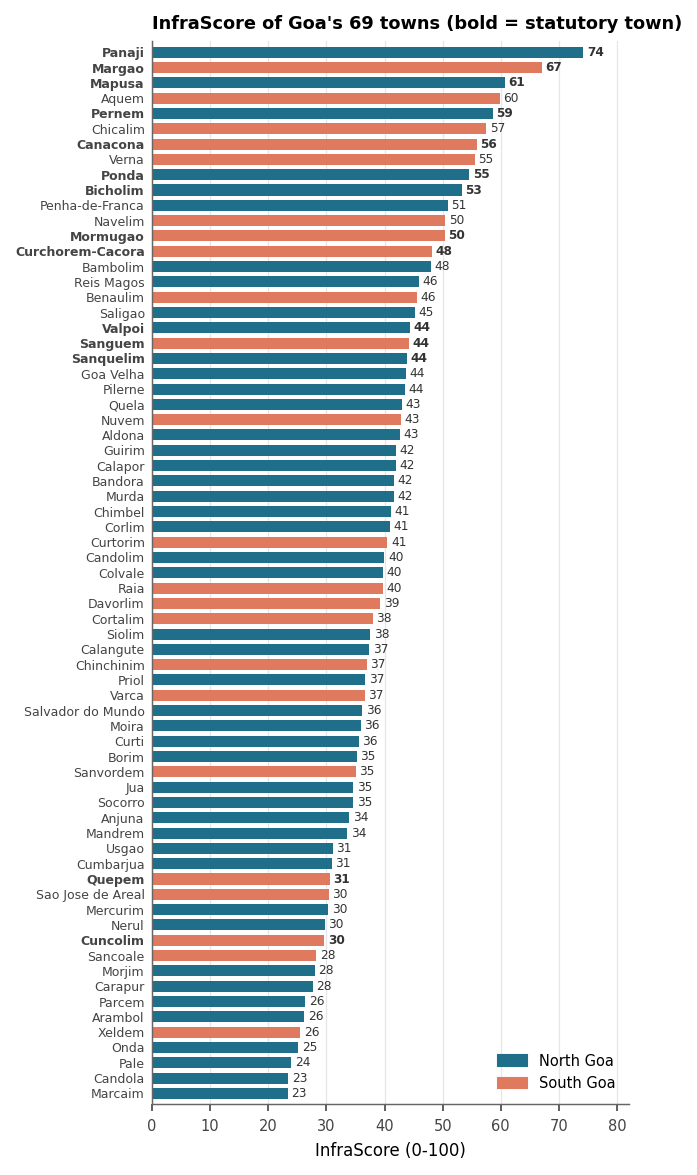

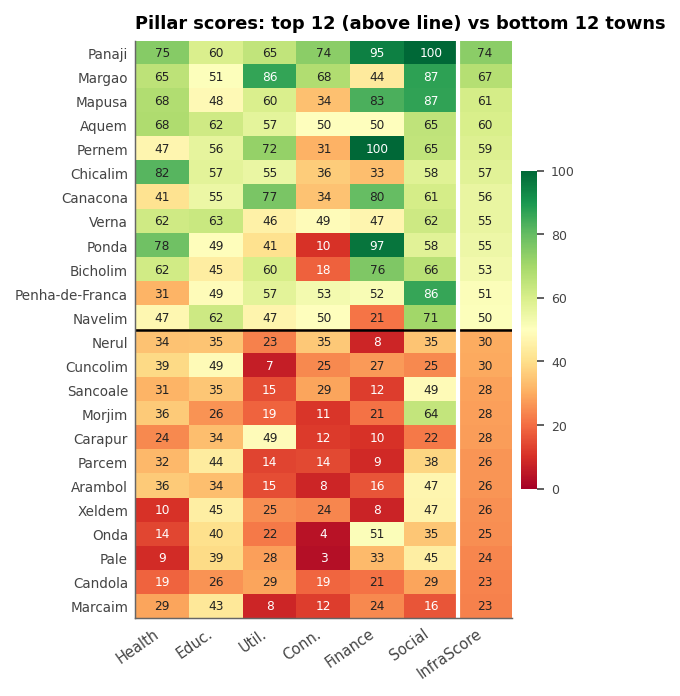

In [7]:
r_ = R.sort_values("infrascore")
fig, ax = plt.subplots(figsize=(COL1 + 0.6, 9.2))
ax.barh(r_["town"], r_["infrascore"], height=0.72, color=np.where(r_["district"] == "North Goa", NORTH, SOUTH))
for y, (s, c) in enumerate(zip(r_["infrascore"], r_["civic_status"])):
    ax.text(s + 0.6, y, f"{s:.0f}", va="center", fontsize=5.8, color="#333333",
            fontweight="bold" if c != "Census Town" else "normal")
ax.set_ylim(-0.7, len(r_) - 0.3); ax.set_xlim(0, 82)
ax.tick_params(axis="y", labelsize=6, length=0); ax.grid(axis="y", visible=False)
for lbl, c in zip(ax.get_yticklabels(), r_["civic_status"]):
    if c != "Census Town":
        lbl.set_fontweight("bold")
ax.set_xlabel("InfraScore (0-100)")
ax.set_title("InfraScore of Goa's 69 towns (bold = statutory town)")
ax.legend([plt.Rectangle((0, 0), 1, 1, color=NORTH), plt.Rectangle((0, 0), 1, 1, color=SOUTH)],
          ["North Goa", "South Goa"], loc="lower right")
savefig(fig, "fig01_infrascore_ranking.png")

sel = pd.concat([R.head(12), R.tail(12)]).set_index("town")[PILLARS + ["infrascore"]]
fig, ax = plt.subplots(figsize=(COL1 + 0.4, 5.0))
im = ax.imshow(sel.values, cmap="RdYlGn", vmin=0, vmax=100, aspect="auto")
ax.set_xticks(range(sel.shape[1]), ["Health", "Educ.", "Util.", "Conn.", "Finance", "Social", "InfraScore"],
              rotation=35, ha="right")
ax.set_yticks(range(len(sel)), sel.index, fontsize=6.5)
ax.grid(False); ax.tick_params(length=0)
for i in range(sel.shape[0]):
    for j in range(sel.shape[1]):
        v = sel.values[i, j]
        ax.text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=5.8, color="white" if v < 20 or v > 85 else "#222222")
ax.axhline(11.5, color="black", lw=1.2)
ax.axvline(5.5, color="white", lw=2)
ax.set_title("Pillar scores: top 12 (above line) vs bottom 12 towns")
cb = fig.colorbar(im, ax=ax, shrink=0.55, pad=0.02); cb.ax.tick_params(labelsize=6); cb.outline.set_visible(False)
savefig(fig, "fig02_pillar_heatmap.png")

## 5. Global uncertainty analysis

Every composite index embeds choices. Following the OECD-JRC handbook and Saisana et al. (2005), we vary all of them jointly:
* distance-decay $\lambda \in \{5, 10, 15\}$ km;
* normalisation of density indicators: winsorised min-max, z-score, percentile rank;
* aggregation: arithmetic vs geometric mean of pillars;
* pillar weights: 200 random draws from a flat Dirichlet distribution per configuration.

That gives 3 x 3 x 2 x 200 = **3,600 scenarios**. For each town we report the median rank and the 5th-95th percentile band.

3,600 scenarios. Spearman rho with baseline ranking: median 0.871, worst single scenario 0.587
Median width of the 90% rank band: 27 places
Always top-10 (95% of scenarios): ['Panaji', 'Margao']
Always bottom-15 (95% of scenarios): ['Marcaim']


median_rho  min_rho
normalisation aggregation                     
minmax        arithmetic        0.902    0.622
              geometric         0.865    0.620
rank          arithmetic        0.883    0.638
              geometric         0.857    0.612
zscore        arithmetic        0.897    0.668
              geometric         0.860    0.594

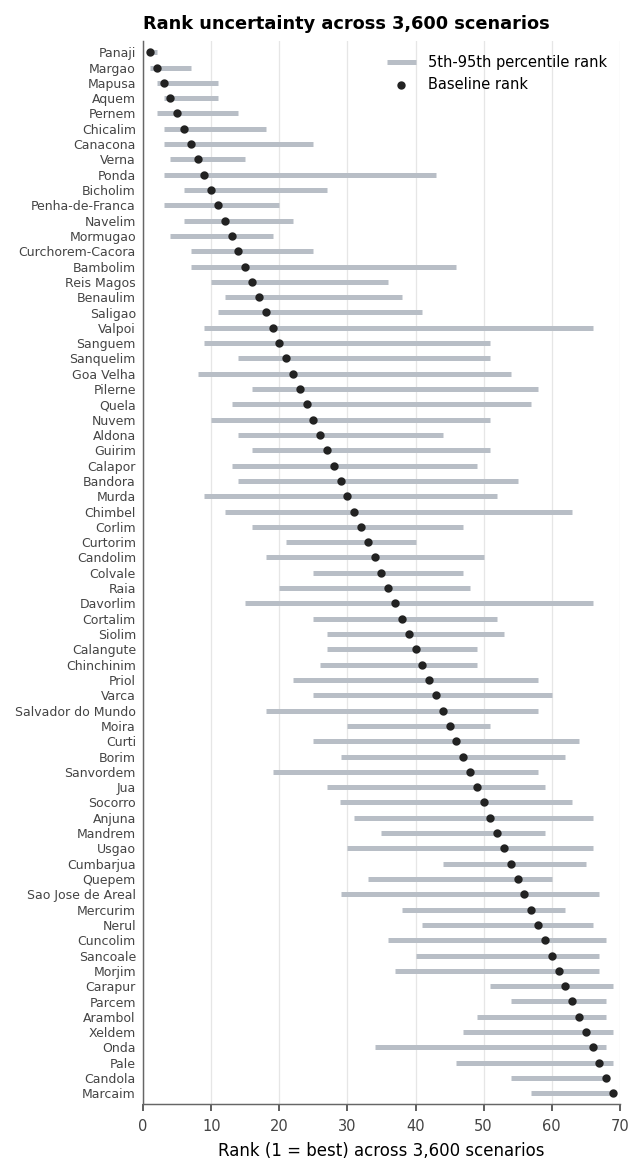

In [8]:
rng = np.random.default_rng(SEED)
W_DRAWS = rng.dirichlet(np.ones(6), size=200)
base_order = R.set_index("census_code").loc[F["census_code"], "infrascore"].values
rank_mat, rho_rows = [], []
for lam in (5, 10, 15):
    for norm in ("minmax", "zscore", "rank"):
        pil = pillar_table(score_indicators(F, BOUNDS, lam=lam, norm=norm))
        for how in ("arithmetic", "geometric"):
            if how == "arithmetic":
                S = pil[PILLARS].values @ W_DRAWS.T
            else:
                S = np.exp(np.log(pil[PILLARS].clip(lower=1).values) @ W_DRAWS.T)
            ranks = pd.DataFrame(S).rank(ascending=False).values
            rank_mat.append(ranks)
            rho = [spearmanr(S[:, k], base_order).statistic for k in range(S.shape[1])]
            rho_rows.append({"lambda_km": lam, "normalisation": norm, "aggregation": how,
                             "median_rho": np.median(rho), "min_rho": np.min(rho)})
RM = np.hstack(rank_mat)                                          # towns x 3600
UA = pd.DataFrame({"census_code": F["census_code"], "rank_median": np.median(RM, 1),
                   "rank_p05": np.percentile(RM, 5, 1), "rank_p95": np.percentile(RM, 95, 1)})
R = R.drop(columns=[c for c in R if c.startswith("rank_")], errors="ignore").merge(UA, on="census_code")
UA_TAB = pd.DataFrame(rho_rows)
print(f"{RM.shape[1]:,} scenarios. Spearman rho with baseline ranking: "
      f"median {UA_TAB.median_rho.median():.3f}, worst single scenario {UA_TAB.min_rho.min():.3f}")
print(f"Median width of the 90% rank band: {(R.rank_p95 - R.rank_p05).median():.0f} places")
top_stable = R[(R.rank_p95 <= 10)]["town"].tolist()
bottom_stable = R[(R.rank_p05 >= 55)]["town"].tolist()
print(f"Always top-10 (95% of scenarios): {top_stable}")
print(f"Always bottom-15 (95% of scenarios): {bottom_stable}")
display(UA_TAB.groupby(["normalisation", "aggregation"])[["median_rho", "min_rho"]].mean().round(3))

r_ = R.sort_values("rank")
fig, ax = plt.subplots(figsize=(COL1 + 0.6, 9.2))
y = np.arange(len(r_))[::-1]
ax.hlines(y, r_["rank_p05"], r_["rank_p95"], color=GREY, lw=2.4, label="5th-95th percentile rank")
ax.scatter(r_["rank"], y, color="#222222", s=9, zorder=3, label="Baseline rank")
ax.set_yticks(y, r_["town"], fontsize=6); ax.tick_params(axis="y", length=0); ax.grid(axis="y", visible=False)
ax.set_ylim(-0.7, len(r_) - 0.3); ax.set_xlim(0, 70)
ax.set_xlabel("Rank (1 = best) across 3,600 scenarios")
ax.set_title("Rank uncertainty across 3,600 scenarios")
ax.legend(loc="upper right")
savefig(fig, "fig03_uncertainty_rank_bands.png")

## 6. Town typologies (unsupervised learning)

A single score says *how much* infrastructure a town has; typologies say *what kind of gap* it has. We compare three algorithms on standardised pillar scores for k = 2..6 using silhouette (higher better), Davies-Bouldin (lower better) and Calinski-Harabasz (higher better), then test **stability**: re-fit on 100 bootstrap samples and measure agreement with the full-data solution (Adjusted Rand Index).

In [9]:
Xc = StandardScaler().fit_transform(R[PILLARS])


def fit_labels(method, k, X, seed=SEED):
    if method == "K-Means":
        m = KMeans(k, n_init=30, random_state=seed).fit(X); return m.labels_, m
    if method == "Ward":
        return AgglomerativeClustering(k, linkage="ward").fit_predict(X), None
    m = GaussianMixture(k, covariance_type="diag", n_init=5, random_state=seed).fit(X)
    return m.predict(X), m


rows = []
for method in ("K-Means", "Ward", "GMM"):
    for k in range(2, 7):
        lab, _ = fit_labels(method, k, Xc)
        rows.append({"method": method, "k": k, "silhouette": silhouette_score(Xc, lab),
                     "davies_bouldin": davies_bouldin_score(Xc, lab), "calinski_harabasz": calinski_harabasz_score(Xc, lab)})
CL_TAB = pd.DataFrame(rows)


def bootstrap_ari(method, k, X, B=100):
    full, _ = fit_labels(method, k, X)
    rng = np.random.default_rng(SEED); aris = []
    for b in range(B):
        idx = rng.choice(len(X), len(X), replace=True)
        lab_b, _ = fit_labels(method, k, X[idx], seed=b)
        cents = np.vstack([X[idx][lab_b == c].mean(0) for c in np.unique(lab_b)])
        pred = np.argmin(((X[:, None, :] - cents[None]) ** 2).sum(-1), axis=1)   # nearest-centroid assignment
        aris.append(adjusted_rand_score(full, pred))
    return np.mean(aris), np.std(aris)


K_FINAL = 4
stab = {m: bootstrap_ari(m, K_FINAL, Xc) for m in ("K-Means", "Ward", "GMM")}
CL_TAB["bootstrap_ARI_k4"] = CL_TAB.apply(lambda r: stab[r.method][0] if r.k == K_FINAL else np.nan, axis=1)
display(CL_TAB.round(3).pivot(index="k", columns="method", values="silhouette").rename_axis("silhouette by k"))
display(CL_TAB[CL_TAB.k == K_FINAL].round(3))
best_method = CL_TAB[CL_TAB.k == K_FINAL].sort_values("bootstrap_ARI_k4", ascending=False).iloc[0]["method"]
print(f"Selected: {best_method}, k = {K_FINAL} (highest bootstrap stability among methods at k = 4)")

method,GMM,K-Means,Ward
silhouette by k,,,
2,0.273,0.281,0.315
3,0.171,0.175,0.163
4,0.197,0.194,0.156
5,0.146,0.178,0.132
6,0.170,0.189,0.151


,method,k,silhouette,davies_bouldin,calinski_harabasz,bootstrap_ARI_k4
2,K-Means,4,0.194,1.503,20.811,0.589
7,Ward,4,0.156,1.512,17.259,0.372
12,GMM,4,0.197,1.329,13.925,0.409


Selected: K-Means, k = 4 (highest bootstrap stability among methods at k = 4)


,n,health,education,utilities,connectivity,finance,social,infrascore
cluster,,,,,,,,
C1 Urban hubs,12,59.5,54.4,52.3,48.1,46.2,73.9,55.5
C2 Taluka centres,13,44.6,53.8,49.8,19.0,65.1,55.8,46.8
C3 Peri-urban,16,42.2,34.7,44.2,39.0,15.1,62.0,39.9
C4 Lagging,28,33.3,38.1,29.5,17.9,24.0,42.8,31.2


C1 Urban hubs (12): Mormugao, Margao, Panaji, Mapusa, Curchorem-Cacora, Penha-de-Franca, Navelim, Nuvem, Chicalim, Bambolim ...
C2 Taluka centres (13): Ponda, Bicholim, Sanquelim, Bandora, Canacona, Valpoi, Priol, Reis Magos, Quela, Sanguem ...
C3 Peri-urban (16): Davorlim, Chimbel, Calapor, Socorro, Curtorim, Benaulim, Raia, Sao Jose de Areal, Candolim, Murda ...
C4 Lagging (28): Sancoale, Cuncolim, Curti, Quepem, Calangute, Usgao, Siolim, Anjuna, Cortalim, Mandrem ...


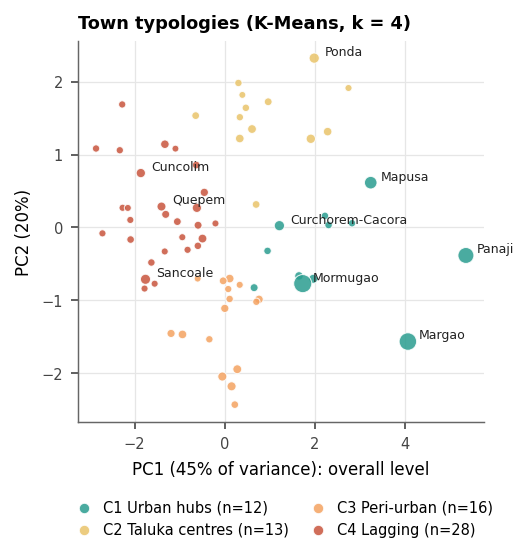

In [10]:
labels, _ = fit_labels(best_method, K_FINAL, Xc)
R["cluster_id"] = labels
prof = R.groupby("cluster_id")[PILLARS + ["infrascore"]].mean().sort_values("infrascore", ascending=False)
order = list(prof.index)
names = {order[0]: "C1 Urban hubs", order[-1]: "C4 Lagging"}
mid = order[1:-1]
fin_minus_conn = {c: prof.loc[c, "finance"] - prof.loc[c, "connectivity"] for c in mid}
mid_sorted = sorted(mid, key=lambda c: -fin_minus_conn[c])
names[mid_sorted[0]] = "C2 Taluka centres"
names[mid_sorted[1]] = "C3 Peri-urban"
R["cluster"] = R["cluster_id"].map(names)
CL_PROF = R.groupby("cluster").agg(n=("town", "count"), **{p: (p, "mean") for p in PILLARS + ["infrascore"]}).round(1)
display(CL_PROF)
for c, g in R.groupby("cluster"):
    print(f"{c} ({len(g)}): {', '.join(g.sort_values('population', ascending=False)['town'].head(10))}{' ...' if len(g) > 10 else ''}")

pcs = PCA(2, random_state=SEED).fit(Xc)
Z = pcs.transform(Xc)
fig, ax = plt.subplots(figsize=(COL1, 3.3))
pal = dict(zip(sorted(R.cluster.unique()), CLUSTER_COLORS))
for c, g in R.groupby("cluster"):
    ax.scatter(Z[g.index, 0], Z[g.index, 1], s=8 + g.population / 1400, color=pal[c], alpha=0.85,
               edgecolor="white", linewidth=0.5, label=f"{c} (n={len(g)})", zorder=3)
lab = list(R.nlargest(6, "population").index) + list(R[R.town.isin(["Cuncolim", "Quepem", "Sancoale", "Ponda"])].index)
lab = list(dict.fromkeys(lab))
label_points(ax, Z[lab, 0], Z[lab, 1], R.town[lab].tolist(), fontsize=6)
ax.set_xlabel(f"PC1 ({pcs.explained_variance_ratio_[0]:.0%} of variance): overall level")
ax.set_ylabel(f"PC2 ({pcs.explained_variance_ratio_[1]:.0%})")
ax.set_title(f"Town typologies ({best_method}, k = 4)")
leg = ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.17), ncol=2, handletextpad=0.3, columnspacing=1.0,
                markerscale=0.8)
for h in leg.legend_handles:
    h.set_sizes([25])
savefig(fig, "fig04_typologies.png")

## 7. Peer-adjusted gap model (supervised regression)

**Question:** given a town's size, density, social composition, civic status and geography, what InfraScore would we *expect*? The residual (actual minus expected) separates genuine under-provision from differences explained by size or status.

**Design**
* Inputs: 10 context variables. **No index ingredient is an input** (no leakage).
* 7 models: mean baseline, Ridge, Lasso, SVR (RBF), k-NN, Random Forest, XGBoost.
* **Nested cross-validation**: hyperparameters tuned by an inner 5-fold grid search inside each outer fold; outer loop = 5-fold x 3 repeats. Reported scores are therefore unbiased by tuning.
* **Ablation**: add feature groups one at a time.
* **Conformal-style intervals**: out-of-fold absolute residuals give a 90% band; a town is *significantly* under-served only if its actual score falls below the band.

In [11]:
GROUPS = {
    "Demand": ["log_population", "log_density", "avg_household_size"],
    "Social": ["sc_share", "st_share", "sex_ratio"],
    "Administrative": ["is_statutory_town", "is_south_goa"],
    "Geography": ["rainfall_mm", "log_area"],
}
CTX = sum(GROUPS.values(), [])
D = F.merge(R[["census_code", "infrascore"]], on="census_code")
X, yv = D[CTX], D["infrascore"]
inner = KFold(5, shuffle=True, random_state=SEED)
outer = RepeatedKFold(n_splits=5, n_repeats=3, random_state=SEED)

MODELS = {
    "Mean baseline": (DummyRegressor(), None),
    "Ridge": (make_pipeline(StandardScaler(), Ridge()), {"ridge__alpha": np.logspace(-2, 3, 12)}),
    "Lasso": (make_pipeline(StandardScaler(), Lasso(max_iter=50000)), {"lasso__alpha": np.logspace(-2, 1, 12)}),
    "SVR (RBF)": (make_pipeline(StandardScaler(), SVR()), {"svr__C": [3, 10, 30, 100], "svr__epsilon": [1, 3]}),
    "k-NN": (make_pipeline(StandardScaler(), KNeighborsRegressor()), {"kneighborsregressor__n_neighbors": [3, 5, 8, 12]}),
    "Random Forest": (RandomForestRegressor(n_estimators=100, max_features=0.5, random_state=SEED),
                      {"min_samples_leaf": [3, 6]}),
}
if HAS_XGB:
    MODELS["XGBoost"] = (XGBRegressor(n_estimators=150, learning_rate=0.05, subsample=0.8, random_state=SEED,
                                      n_jobs=1, verbosity=0), {"max_depth": [1, 2, 3]})


def tuned(est, grid):
    return GridSearchCV(est, grid, cv=inner, scoring="neg_mean_absolute_error") if grid else est


rows = []
for name, (est, grid) in MODELS.items():
    t = time.time()
    cv = cross_validate(tuned(est, grid), X, yv, cv=outer, scoring=("neg_mean_absolute_error", "r2"))
    rows.append({"model": name, "MAE": -cv["test_neg_mean_absolute_error"].mean(),
                 "MAE_sd": cv["test_neg_mean_absolute_error"].std(), "R2": cv["test_r2"].mean(),
                 "seconds": time.time() - t})
GAP_TAB = pd.DataFrame(rows).sort_values("MAE").reset_index(drop=True)
BEST = GAP_TAB[GAP_TAB.model != "Mean baseline"].iloc[0]["model"]
base_mae = GAP_TAB.set_index("model").loc["Mean baseline", "MAE"]
best_mae = GAP_TAB.set_index("model").loc[BEST, "MAE"]
print(f"Selected model: {BEST} (nested-CV MAE {best_mae:.2f} vs baseline {base_mae:.2f}; "
      f"{1 - best_mae / base_mae:.0%} lower error)")
display(GAP_TAB.round(3))

Selected model: Lasso (nested-CV MAE 6.80 vs baseline 8.53; 20% lower error)


,model,MAE,MAE_sd,R2,seconds
0,Lasso,6.796,1.280,0.239,7.080
1,Ridge,7.014,1.406,0.202,8.575
2,Random Forest,7.448,1.459,0.121,21.676
3,k-NN,7.565,1.150,0.116,2.582
4,XGBoost,7.630,1.550,0.051,9.482
5,SVR (RBF),7.772,1.443,0.054,4.925
6,Mean baseline,8.528,1.277,-0.146,0.058


,features,n_features,MAE,R2
0,Demand,3,7.671,0.034
1,Demand + Social,6,7.872,-0.009
2,Demand + Social + Administrative,8,7.368,0.100
3,Demand + Social + Administrative + Geography,10,6.796,0.239


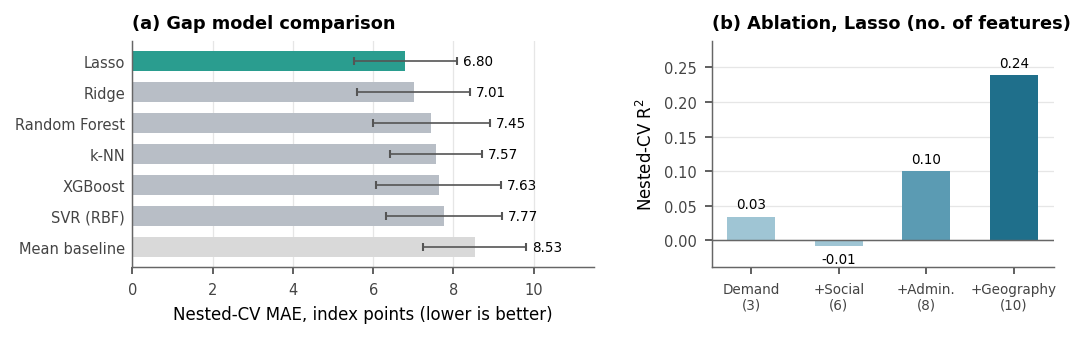

In [12]:
# ---- ablation with the selected model family
rows, cols = [], []
for gname, gcols in GROUPS.items():
    cols = cols + gcols
    est, grid = MODELS[BEST]
    cv = cross_validate(tuned(est, grid), D[cols], yv, cv=outer, scoring=("neg_mean_absolute_error", "r2"))
    rows.append({"features": " + ".join(list(GROUPS)[:list(GROUPS).index(gname) + 1]), "n_features": len(cols),
                 "MAE": -cv["test_neg_mean_absolute_error"].mean(), "R2": cv["test_r2"].mean()})
ABL_TAB = pd.DataFrame(rows)
display(ABL_TAB.round(3))

fig, axes = plt.subplots(1, 2, figsize=(COL2, 2.3), gridspec_kw={"width_ratios": [1.35, 1]})
g = GAP_TAB.sort_values("MAE", ascending=False)
cols_ = ["#2a9d8f" if m == BEST else ("#d9d9d9" if m == "Mean baseline" else GREY) for m in g.model]
axes[0].barh(g.model, g.MAE, xerr=g.MAE_sd, color=cols_, height=0.65,
             error_kw=dict(ecolor="#555555", lw=0.8, capsize=2))
for yy, (m, sd) in enumerate(zip(g.MAE, g.MAE_sd)):
    axes[0].text(m + sd + 0.15, yy, f"{m:.2f}", va="center", fontsize=6.5)
axes[0].set_xlim(0, 11.5); axes[0].grid(axis="y", visible=False); axes[0].tick_params(axis="y", length=0)
axes[0].set_xlabel("Nested-CV MAE, index points (lower is better)")
axes[0].set_title("(a) Gap model comparison")
abl_lbl = [f"{n}\n({k})" for n, k in zip(["Demand", "+Social", "+Admin.", "+Geography"], ABL_TAB.n_features)]
bars = axes[1].bar(abl_lbl, ABL_TAB.R2, color=["#9fc5d4", "#9fc5d4", "#5b9bb3", NORTH], width=0.55)
axes[1].tick_params(axis="x", labelsize=6.5)
for b, v in zip(bars, ABL_TAB.R2):
    axes[1].text(b.get_x() + b.get_width() / 2, v + (0.008 if v >= 0 else -0.008), f"{v:.2f}", ha="center",
                 va="bottom" if v >= 0 else "top", fontsize=6.5)
axes[1].axhline(0, color="#666666", lw=0.7)
axes[1].set_ylim(min(ABL_TAB.R2.min(), 0) - 0.03, max(ABL_TAB.R2) + 0.05); axes[1].grid(axis="x", visible=False)
axes[1].set_ylabel("Nested-CV R$^2$")
axes[1].set_title(f"(b) Ablation, {BEST} (no. of features)")
fig.tight_layout(w_pad=2.5)
savefig(fig, "fig05_model_comparison_ablation.png")

In [13]:
# ---- out-of-fold expected scores (averaged over 5 shuffles) and conformal intervals
est, grid = MODELS[BEST]
oof = np.mean([cross_val_predict(tuned(est, grid), X, yv, cv=KFold(5, shuffle=True, random_state=s)) for s in range(5)], axis=0)
GAP = D[["census_code", "town", "district", "civic_status", "population", "infrascore"]].copy()
GAP["expected"] = oof
GAP["gap"] = GAP["infrascore"] - GAP["expected"]
q90 = np.quantile(np.abs(GAP["gap"]), 0.90)
GAP["lower_90"], GAP["upper_90"] = GAP["expected"] - q90, GAP["expected"] + q90
GAP["flag"] = np.select([GAP.infrascore < GAP.lower_90, GAP.infrascore > GAP.upper_90],
                        ["Significantly under-served", "Significantly over-performing"], "Within expected range")
GAP = GAP.sort_values("gap").reset_index(drop=True)
print(f"90% interval half-width: +/- {q90:.1f} points")
print(GAP.flag.value_counts().to_string())
display(GAP[GAP.flag != "Within expected range"][["town", "civic_status", "infrascore", "expected", "gap", "flag"]].round(1))
display(Markdown("**Ten largest negative gaps (watch list)**"))
display(GAP.head(10)[["town", "civic_status", "population", "infrascore", "expected", "gap", "flag"]].round(1))

90% interval half-width: +/- 13.1 points
flag
Within expected range            62
Significantly over-performing     4
Significantly under-served        3


,town,civic_status,infrascore,expected,gap,flag
0,Cuncolim,Municipal Council,29.6,48.9,-19.3,Significantly under-served
1,Quepem,Municipal Council,30.6,47.5,-16.9,Significantly under-served
2,Sancoale,Census Town,28.3,43.4,-15.2,Significantly under-served
65,Aquem,Census Town,59.8,41.0,18.9,Significantly over-performing
66,Chicalim,Census Town,57.5,37.5,19.9,Significantly over-performing
67,Verna,Census Town,55.5,33.2,22.3,Significantly over-performing
68,Panaji,Municipal Corporation,74.2,51.2,23.0,Significantly over-performing


**Ten largest negative gaps (watch list)**

,town,civic_status,population,infrascore,expected,gap,flag
0,Cuncolim,Municipal Council,16623,29.6,48.9,-19.3,Significantly under-served
1,Quepem,Municipal Council,14795,30.6,47.5,-16.9,Significantly under-served
2,Sancoale,Census Town,21923,28.3,43.4,-15.2,Significantly under-served
3,Cumbarjua,Census Town,4917,30.9,43.5,-12.5,Within expected range
4,Arambol,Census Town,5322,26.2,37.6,-11.4,Within expected range
5,Mercurim,Census Town,4970,30.3,40.8,-10.5,Within expected range
6,Parcem,Census Town,4627,26.4,36.6,-10.2,Within expected range
7,Xeldem,Census Town,7434,25.5,35.7,-10.2,Within expected range
8,Mormugao,Municipal Council,94393,50.4,60.4,-10.0,Within expected range
9,Marcaim,Census Town,6215,23.3,33.1,-9.8,Within expected range


,feature,coef_per_SD
6,is_statutory_town,3.89
8,rainfall_mm,-2.49
1,log_density,2.34
0,log_population,0.86
5,sex_ratio,-0.75
2,avg_household_size,-0.00
4,st_share,-0.00
3,sc_share,0.00
7,is_south_goa,0.00
9,log_area,-0.00


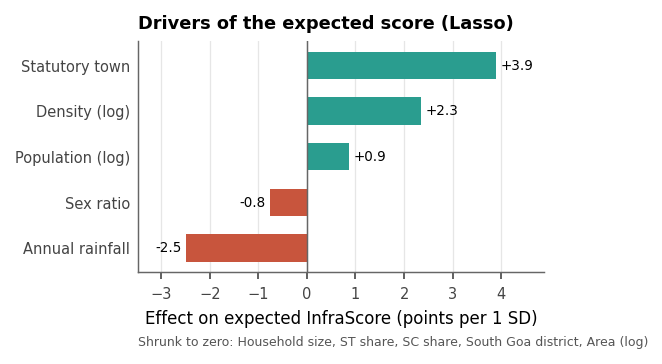

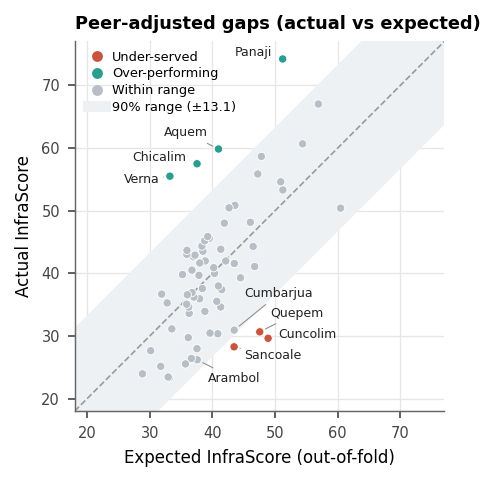

In [14]:
# ---- explanation: fit on all data; for linear models contributions are exact (coef x standardised value)
final = tuned(est, grid).fit(X, yv)
model = final.best_estimator_ if hasattr(final, "best_estimator_") else final
if BEST in ("Ridge", "Lasso"):
    lin = model[-1]
    Zs = model[0].transform(X)
    COEF = pd.DataFrame({"feature": CTX, "coef_per_SD": lin.coef_}).sort_values("coef_per_SD", key=abs, ascending=False)
    CONTRIB = pd.DataFrame(Zs * lin.coef_, columns=CTX, index=D["town"])
else:
    from sklearn.inspection import permutation_importance
    pi = permutation_importance(model, X, yv, n_repeats=30, random_state=SEED)
    COEF = pd.DataFrame({"feature": CTX, "coef_per_SD": pi.importances_mean}).sort_values("coef_per_SD", ascending=False)
    CONTRIB = None
display(COEF.round(2))

nz = COEF[COEF.coef_per_SD.abs() > 1e-6].sort_values("coef_per_SD")
zeroed = [PRETTY.get(f, f) for f in COEF[COEF.coef_per_SD.abs() <= 1e-6].feature]
fig, ax = plt.subplots(figsize=(COL1, 2.0))
ax.barh([PRETTY.get(f, f) for f in nz.feature], nz.coef_per_SD, height=0.6,
        color=np.where(nz.coef_per_SD >= 0, "#2a9d8f", "#c8553d"))
for yy, v in enumerate(nz.coef_per_SD):
    ax.text(v + (0.1 if v >= 0 else -0.1), yy, f"{v:+.1f}", va="center", ha="left" if v >= 0 else "right", fontsize=6.5)
ax.axvline(0, color="#666666", lw=0.7); ax.grid(axis="y", visible=False); ax.tick_params(axis="y", length=0)
ax.set_xlim(nz.coef_per_SD.min() - 1, nz.coef_per_SD.max() + 1)
ax.set_xlabel("Effect on expected InfraScore (points per 1 SD)")
ax.set_title(f"Drivers of the expected score ({BEST})")
if zeroed:
    ax.text(0, -0.32, "Shrunk to zero: " + ", ".join(zeroed), transform=ax.transAxes, fontsize=6, color="#555555")
savefig(fig, "fig06_gap_drivers.png")

from matplotlib.lines import Line2D
from matplotlib.patches import Patch
FLAG_COL = {"Significantly under-served": "#c8553d", "Significantly over-performing": "#2a9d8f",
            "Within expected range": GREY}
fig, ax = plt.subplots(figsize=(COL1, 3.2))
lo = np.floor(min(GAP.expected.min(), GAP.infrascore.min()) / 5) * 5 - 2
hi = np.ceil(max(GAP.expected.max(), GAP.infrascore.max()) / 5) * 5 + 2
xx = np.linspace(lo, hi, 10)
ax.fill_between(xx, xx - q90, xx + q90, color="#eef1f4", zorder=1)
ax.plot(xx, xx, "--", color="#999999", lw=0.8, zorder=2)
ax.scatter(GAP.expected, GAP.infrascore, c=GAP.flag.map(FLAG_COL), s=16, edgecolor="white", linewidth=0.4, zorder=3)
lab = GAP[(GAP.flag != "Within expected range") | (GAP.gap.rank() <= 5)]
label_points(ax, lab.expected.values, lab.infrascore.values, lab.town.tolist(), fontsize=6,
             sides=["l" if f == "Significantly over-performing" else "r" for f in lab.flag])
ax.set_xlim(lo, hi); ax.set_ylim(lo, hi); ax.set_aspect("equal", adjustable="box")
ax.set_xlabel("Expected InfraScore (out-of-fold)"); ax.set_ylabel("Actual InfraScore")
ax.set_title("Peer-adjusted gaps (actual vs expected)")
ax.legend(handles=[Line2D([], [], marker="o", ls="", color=FLAG_COL["Significantly under-served"], label="Under-served"),
                   Line2D([], [], marker="o", ls="", color=FLAG_COL["Significantly over-performing"], label="Over-performing"),
                   Line2D([], [], marker="o", ls="", color=GREY, label="Within range"),
                   Patch(color="#eef1f4", label=f"90% range (±{q90:.1f})")],
          loc="upper left", handletextpad=0.2, borderaxespad=0.3, markerscale=0.7, fontsize=6.2, labelspacing=0.3)
savefig(fig, "fig07_gap_actual_vs_expected.png")

## 8. Facility presence model (supervised classification)

For six facility types we ask: *does this town have one, and should it?* A classifier learns, from the same 10 context variables, which towns typically host each facility. Towns that **lack** the facility but receive a **high out-of-fold probability** look like towns that do have it: they are candidate sites. This is the shortlist the policy simulation draws from.

Metrics suit imbalanced classes: ROC-AUC, PR-AUC (compared with prevalence, the no-skill level), F1 and Brier score. Evaluation: repeated stratified 5-fold CV (3 repeats), class-balanced weights.

,facility,model,positives,prevalence,ROC_AUC,PR_AUC,F1,Brier
0,Private bank,Logistic (L2),32,0.464,0.846,0.862,0.721,0.156
1,Private bank,Random Forest,32,0.464,0.807,0.816,0.667,0.176
2,Co-operative bank,Logistic (L2),43,0.623,0.727,0.829,0.694,0.216
3,Co-operative bank,Random Forest,43,0.623,0.718,0.826,0.750,0.205
4,Public library,Logistic (L2),40,0.580,0.682,0.725,0.649,0.225
5,Public library,Random Forest,40,0.580,0.685,0.759,0.753,0.221
6,Auditorium / community hall,Logistic (L2),32,0.464,0.583,0.609,0.459,0.246
7,Auditorium / community hall,Random Forest,32,0.464,0.574,0.581,0.533,0.250
8,Degree college,Logistic (L2),13,0.188,0.669,0.514,0.412,0.188
9,Degree college,Random Forest,13,0.188,0.702,0.446,0.417,0.149


Mean ROC-AUC by model: {'Logistic (L2)': 0.695, 'Random Forest': 0.681} -> using Logistic (L2)

61 candidate sites (facility absent, out-of-fold probability >= 0.5)


,top candidates
facility,
Auditorium / community hall,"Cuncolim, Quepem, Priol, Marcaim, Onda, Calangute"
Co-operative bank,"Socorro, Davorlim, Sao Jose de Areal, Candolim"
Degree college,"Curchorem-Cacora, Sancoale, Bicholim, Sanqueli..."
Private bank,"Curtorim, Benaulim, Jua, Murda, Sao Jose de Ar..."
Public library,"Cuncolim, Bambolim, Usgao, Socorro, Marcaim, C..."
Stadium,"Ponda, Cuncolim, Bicholim, Siolim, Sancoale, C..."


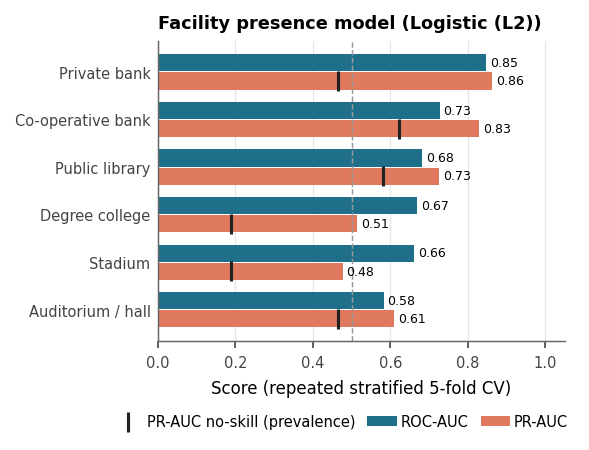

In [15]:
TARGETS = {
    "Private bank": raw["n_private_commercial_bank"] > 0,
    "Co-operative bank": raw["n_co_operative_bank"] > 0,
    "Public library": F["acc_library_km"] == 0,
    "Auditorium / community hall": F["acc_auditorium_km"] == 0,
    "Degree college": F["acc_degree_college_km"] == 0,
    "Stadium": F["acc_stadium_km"] == 0,
}
CLF = {
    "Logistic (L2)": GridSearchCV(make_pipeline(StandardScaler(), LogisticRegression(class_weight="balanced", max_iter=5000)),
                                  {"logisticregression__C": [0.1, 0.3, 1, 3]}, cv=StratifiedKFold(5, shuffle=True, random_state=SEED),
                                  scoring="roc_auc"),
    "Random Forest": RandomForestClassifier(n_estimators=100, min_samples_leaf=3, class_weight="balanced", random_state=SEED),
}
rows, PROBS = [], {}
for tname, yt in TARGETS.items():
    yt = yt.astype(int).values
    for mname, clf in CLF.items():
        probs = np.mean([cross_val_predict(clf, X, yt, cv=StratifiedKFold(5, shuffle=True, random_state=s),
                                           method="predict_proba")[:, 1] for s in range(3)], axis=0)
        rows.append({"facility": tname, "model": mname, "positives": int(yt.sum()), "prevalence": yt.mean(),
                     "ROC_AUC": roc_auc_score(yt, probs), "PR_AUC": average_precision_score(yt, probs),
                     "F1": f1_score(yt, probs >= 0.5), "Brier": brier_score_loss(yt, probs)})
        PROBS[(tname, mname)] = probs
FAC_TAB = pd.DataFrame(rows)
display(FAC_TAB.round(3))
best_clf = FAC_TAB.groupby("model")["ROC_AUC"].mean().idxmax()
print(f"Mean ROC-AUC by model: {FAC_TAB.groupby('model')['ROC_AUC'].mean().round(3).to_dict()} -> using {best_clf}")

cand = []
for tname, yt in TARGETS.items():
    p = PROBS[(tname, best_clf)]
    for i in np.where((~yt.values) & (p >= 0.5))[0]:
        cand.append({"facility": tname, "town": F.town[i], "census_code": F.census_code[i],
                     "probability": p[i], "population": F.population[i]})
CAND = pd.DataFrame(cand).sort_values(["facility", "probability"], ascending=[True, False])
print(f"\n{len(CAND)} candidate sites (facility absent, out-of-fold probability >= 0.5)")
display(CAND.groupby("facility").apply(lambda g: ", ".join(g.town.head(6))).rename("top candidates").to_frame())

fb = FAC_TAB[FAC_TAB.model == best_clf].set_index("facility").sort_values("ROC_AUC")
fig, ax = plt.subplots(figsize=(COL1, 2.6))
yi = np.arange(len(fb))
ax.barh(yi + 0.19, fb.ROC_AUC, 0.36, color=NORTH, label="ROC-AUC")
ax.barh(yi - 0.19, fb.PR_AUC, 0.36, color=SOUTH, label="PR-AUC")
ax.scatter(fb.prevalence, yi - 0.19, marker="|", s=90, color="#222222", zorder=3, label="PR-AUC no-skill (prevalence)")
for k, (a, p) in enumerate(zip(fb.ROC_AUC, fb.PR_AUC)):
    ax.text(a + 0.01, k + 0.19, f"{a:.2f}", va="center", fontsize=6)
    ax.text(p + 0.01, k - 0.19, f"{p:.2f}", va="center", fontsize=6)
ax.axvline(0.5, color="#999999", ls="--", lw=0.7)
ax.set_yticks(yi, [f.replace("Auditorium / community hall", "Auditorium / hall") for f in fb.index])
ax.set_xlim(0, 1.05); ax.grid(axis="y", visible=False); ax.tick_params(axis="y", length=0)
ax.set_xlabel("Score (repeated stratified 5-fold CV)")
ax.set_title(f"Facility presence model ({best_clf})")
ax.legend(loc="upper center", bbox_to_anchor=(0.45, -0.2), ncol=3, handletextpad=0.3, columnspacing=0.8)
savefig(fig, "fig08_facility_model.png")

## 9. Policy simulation: where should the next investments go?

**Decision problem.** A planner can fund *K* interventions (each one facility in one town). Which set maximises benefit?

* **Action menu:** add a primary health centre, a hospital, a fire station, a bank branch (feasible only where the bank models give probability >= 0.5 or a bank already exists), or one of the facilities from Section 8 at its candidate sites.
* **Re-scoring:** the town's indicators are updated and re-scored with the *frozen* baseline scaler, so scores stay comparable.
* **Objective (equity-weighted):** benefit = population x score gain x $(100-\text{IS})/(100-\overline{\text{IS}})$, giving more weight to gains in weaker towns.
* **Strategies compared:** (1) greedy model-guided optimiser, (2) largest towns first, (3) lowest-score towns first, (4) random feasible actions (mean of 200 runs).

Interventions are counted in equal units; no cost data are assumed.

Simulation time 2s | baseline Gini 0.1469


,budget_K,strategy,pop_weighted_gain,mean_gain,towns_left_tier_E,gini_after,gain_in_bottom_quintile
0,5,Greedy optimiser,0.439,0.308,2.000,0.143,12.229
1,5,Largest towns first,0.025,0.004,0.000,0.147,0.000
2,5,Lowest score first,0.177,0.376,0.000,0.137,25.978
3,5,Random (mean),0.088,0.127,0.400,0.146,3.442
4,10,Greedy optimiser,0.762,0.603,2.000,0.141,15.768
5,10,Largest towns first,0.051,0.007,0.000,0.147,0.000
6,10,Lowest score first,0.396,0.735,5.000,0.130,50.721
7,10,Random (mean),0.177,0.267,0.733,0.145,5.539
8,20,Greedy optimiser,1.298,1.218,3.000,0.139,26.213
9,20,Largest towns first,0.102,0.014,0.000,0.147,0.000


**Greedy plan for K = 10 interventions**

,step,town,action,gain
0,1,Cuncolim,Fire station,5.45
1,2,Sancoale,Fire station,3.67
2,3,Curchorem-Cacora,Hospital,4.32
3,4,Sancoale,Hospital,3.11
4,5,Usgao,Hospital,4.72
5,6,Quepem,Hospital,3.94
6,7,Cuncolim,Hospital,3.54
7,8,Usgao,Fire station,4.66
8,9,Quepem,Fire station,3.67
9,10,Sanquelim,Hospital,4.55


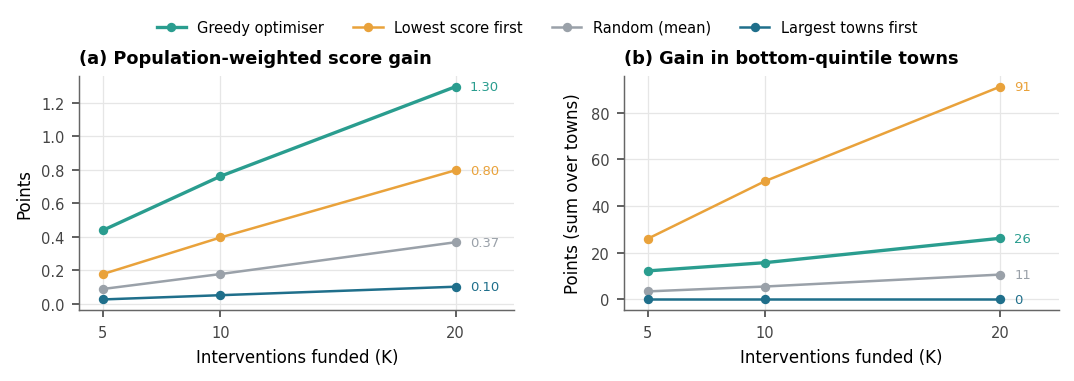

In [16]:
IS0 = aggregate(PIL, BASE_W).values
POP = F["population"].values
MEAN_IS = IS0.mean()
cand_set = set(zip(CAND.facility, CAND.census_code))
bank_ok = (raw["n_private_commercial_bank"] + raw["n_co_operative_bank"] + raw["n_nationalised_bank"] > 0).values | \
          np.isin(F.census_code, CAND[CAND.facility.str.contains("bank")].census_code)
ACTIONS = ["Primary health centre", "Hospital", "Fire station", "Bank branch", "Public library",
           "Auditorium / community hall", "Degree college", "Stadium"]


def apply(row, action):
    r = dict(row)
    if action == "Primary health centre": r["primary_care_per_10k"] += 10_000 / r["population"]
    elif action == "Hospital": r["hospitals_per_10k"] += 10_000 / r["population"]; r["acc_hospital_km"] = 0.0
    elif action == "Fire station": r["acc_fire_km"] = 0.0
    elif action == "Bank branch": r["banks_per_10k"] += 10_000 / r["population"]
    elif action == "Public library": r["acc_library_km"] = 0.0
    elif action == "Auditorium / community hall": r["acc_auditorium_km"] = 0.0
    elif action == "Degree college": r["acc_degree_college_km"] = 0.0
    elif action == "Stadium": r["acc_stadium_km"] = 0.0
    return r


def feasible(i, action, state):
    if action in ("Public library", "Auditorium / community hall", "Degree college", "Stadium"):
        return (action, F.census_code[i]) in cand_set and state[i][{"Public library": "acc_library_km",
                "Auditorium / community hall": "acc_auditorium_km", "Degree college": "acc_degree_college_km",
                "Stadium": "acc_stadium_km"}[action]] > 0
    if action == "Hospital": return state[i]["acc_hospital_km"] > 0
    if action == "Fire station": return state[i]["acc_fire_km"] > 0
    if action == "Bank branch": return bank_ok[i]
    return True


IND_ITEMS = list(INDICATORS.items())
W_NORM = {p: BASE_W[p] / sum(BASE_W.values()) for p in PILLARS}


def rescore(row, lam=10.0):
    """Fast scalar version of score_indicators -> pillar_table -> aggregate (baseline settings, frozen bounds)."""
    acc = {p: [] for p in PILLARS}
    for c, (pil, kind) in IND_ITEMS:
        v = row[c]
        if kind == "access":
            sc = 100 * np.exp(-v / lam)
        elif kind == "ratio":
            sc = 100 * v
        else:
            lo, hi = BOUNDS[c][0], BOUNDS[c][1]
            sc = 100 * (min(max(v, lo), hi) - lo) / (hi - lo)
        acc[pil].append(sc)
    return sum(W_NORM[p] * np.mean(acc[p]) for p in PILLARS)


assert abs(rescore(F.iloc[0]) - IS0[0]) < 1e-9, "fast re-scorer must match the index"


def best_action_gain(i, state, cur):
    best = (None, 0.0, None)
    for a in ACTIONS:
        if feasible(i, a, state):
            new_row = apply(state[i], a)
            g = rescore(new_row) - cur[i]
            if g > best[1]:
                best = (a, g, new_row)
    return best


def equity_benefit(i, gain, cur):
    return POP[i] * gain * (100 - cur[i]) / (100 - MEAN_IS)


def run(strategy, K, seed=0):
    state, cur, plan = F.to_dict("records"), IS0.copy(), []
    rng = np.random.default_rng(seed)
    for _ in range(K):
        if strategy == "Greedy optimiser":
            opts = [(equity_benefit(i, *best_action_gain(i, state, cur)[1:2], cur), i) for i in range(len(F))]
            _, i = max(opts)
        elif strategy == "Largest towns first":
            i = next(j for j in np.argsort(-POP) if best_action_gain(j, state, cur)[0])
        elif strategy == "Lowest score first":
            i = next(j for j in np.argsort(cur) if best_action_gain(j, state, cur)[0])
        else:   # random feasible action
            while True:
                i, a = rng.integers(len(F)), ACTIONS[rng.integers(len(ACTIONS))]
                if feasible(i, a, state):
                    new_row = apply(state[i], a); break
        if strategy != "Random":
            a, g, new_row = best_action_gain(i, state, cur)
        state[i] = new_row
        new = rescore(new_row)
        plan.append({"step": len(plan) + 1, "town": F.town[i], "action": a, "gain": new - cur[i]})
        cur[i] = new
    return cur, pd.DataFrame(plan)


def metrics(cur):
    e_cut = np.quantile(IS0, 0.2)
    gini = lambda v: np.abs(v[:, None] - v[None]).mean() / (2 * v.mean())
    return {"pop_weighted_gain": np.average(cur - IS0, weights=POP), "mean_gain": (cur - IS0).mean(),
            "towns_left_tier_E": int(((IS0 <= e_cut) & (cur > e_cut)).sum()), "gini_after": gini(cur),
            "gain_in_bottom_quintile": (cur - IS0)[IS0 <= e_cut].sum()}


t = time.time()
rows, PLANS = [], {}
for K in (5, 10, 20):
    for strat in ("Greedy optimiser", "Largest towns first", "Lowest score first"):
        cur, plan = run(strat, K)
        rows.append({"budget_K": K, "strategy": strat, **metrics(cur)}); PLANS[(strat, K)] = plan
    rnd = [metrics(run("Random", K, seed=s)[0]) for s in range(30)]
    rows.append({"budget_K": K, "strategy": "Random (mean)", **pd.DataFrame(rnd).mean().to_dict()})
SIM = pd.DataFrame(rows)
print(f"Simulation time {time.time() - t:.0f}s | baseline Gini {metrics(IS0)['gini_after']:.4f}")
display(SIM.round(3))
display(Markdown("**Greedy plan for K = 10 interventions**"))
display(PLANS[("Greedy optimiser", 10)].round(2))

fig, axes = plt.subplots(1, 2, figsize=(COL2, 2.35))
order_ = ["Greedy optimiser", "Lowest score first", "Random (mean)", "Largest towns first"]
for strat in order_:
    s = SIM[SIM.strategy == strat]
    kw = dict(color=STRAT_COLORS[strat], marker="o", ms=3.5, lw=1.6 if strat == "Greedy optimiser" else 1.2)
    axes[0].plot(s.budget_K, s.pop_weighted_gain, label=strat, **kw)
    axes[1].plot(s.budget_K, s.gain_in_bottom_quintile, **kw)
    axes[0].text(20.6, s.pop_weighted_gain.iloc[-1], f"{s.pop_weighted_gain.iloc[-1]:.2f}", va="center",
                 fontsize=6.3, color=STRAT_COLORS[strat])
    axes[1].text(20.6, s.gain_in_bottom_quintile.iloc[-1], f"{s.gain_in_bottom_quintile.iloc[-1]:.0f}", va="center",
                 fontsize=6.3, color=STRAT_COLORS[strat])
for a in axes:
    a.set_xticks([5, 10, 20]); a.set_xlim(4, 22.5); a.set_xlabel("Interventions funded (K)")
axes[0].set_ylabel("Points"); axes[1].set_ylabel("Points (sum over towns)")
axes[0].set_title("(a) Population-weighted score gain")
axes[1].set_title("(b) Gain in bottom-quintile towns")
fig.legend(*axes[0].get_legend_handles_labels(), loc="upper center", ncol=4, bbox_to_anchor=(0.5, 1.07))
fig.tight_layout(w_pad=3)
savefig(fig, "fig09_policy_simulation.png")

### 9b. Cost-aware allocation and robustness to cost assumptions

Facilities do not cost the same. We repeat the simulation with a **budget in cost units** (1 unit = one primary health centre) and a cost-aware greedy rule that maximises *benefit per unit cost*.

Exact unit costs are not published for Goa, so we use **illustrative relative costs**, anchored on one reported figure (a 120-bed sub-district hospital at Chicalim built for about Rs 30 crore, Herald Goa), and then test whether the conclusion survives **200 random cost scenarios** in which every cost is multiplied by an independent log-normal factor (about ±50%).

In [17]:
BASE_COST = {"Primary health centre": 1.0, "Hospital": 6.0, "Fire station": 2.0, "Bank branch": 0.5,
             "Public library": 0.5, "Auditorium / community hall": 1.0, "Degree college": 5.0, "Stadium": 3.0}
BUDGET = 20.0


def town_options(i, state, cur):
    """All feasible actions for town i with their score gain and new row."""
    opts = []
    for a in ACTIONS:
        if feasible(i, a, state):
            new_row = apply(state[i], a)
            g = rescore(new_row) - cur[i]
            if g > 1e-9:
                opts.append((a, g, new_row))
    return opts


def run_budget(strategy, cost, budget=BUDGET, seed=0):
    state, cur, spent, plan = F.to_dict("records"), IS0.copy(), 0.0, []
    cache = {i: town_options(i, state, cur) for i in range(len(F))}
    rng = np.random.default_rng(seed)
    while True:
        left = budget - spent
        cands = [(i, a, g, row) for i, ops in cache.items() for a, g, row in ops if cost[a] <= left + 1e-9]
        if not cands:
            break
        if strategy == "Cost-aware greedy":
            i, a, g, row = max(cands, key=lambda c: equity_benefit(c[0], c[2], cur) / cost[c[1]])
        elif strategy == "Greedy (ignores cost)":
            i, a, g, row = max(cands, key=lambda c: equity_benefit(c[0], c[2], cur))
        elif strategy == "Lowest score first":
            j = min({c[0] for c in cands}, key=lambda t: cur[t])
            i, a, g, row = max([c for c in cands if c[0] == j], key=lambda c: c[2])
        else:
            i, a, g, row = cands[rng.integers(len(cands))]
        state[i] = row
        cur[i] = rescore(row)
        spent += cost[a]
        plan.append({"town": F.town[i], "action": a, "cost": cost[a], "gain": g})
        cache[i] = town_options(i, state, cur)
    return cur, pd.DataFrame(plan)


STRATS_B = ["Cost-aware greedy", "Greedy (ignores cost)", "Lowest score first", "Random"]
t = time.time()
base_rows, BUDGET_PLANS = [], {}
for s_ in STRATS_B:
    reps = 10 if s_ == "Random" else 1
    res = [run_budget(s_, BASE_COST, seed=k) for k in range(reps)]
    m = pd.DataFrame([metrics(c) for c, _ in res]).mean()
    base_rows.append({"strategy": s_, "interventions": np.mean([len(p) for _, p in res]), **m.to_dict()})
    BUDGET_PLANS[s_] = res[0][1]
COST_TAB = pd.DataFrame(base_rows)

rng = np.random.default_rng(SEED)
mc = []
for d in range(200):
    cost = {a: c * float(np.exp(rng.normal(0, 0.4))) for a, c in BASE_COST.items()}
    row = {}
    for s_ in STRATS_B[:3]:
        row[s_] = metrics(run_budget(s_, cost)[0])["pop_weighted_gain"]
    row["Random"] = metrics(run_budget("Random", cost, seed=d)[0])["pop_weighted_gain"]
    mc.append(row)
MC = pd.DataFrame(mc)
win = {s_: (MC["Cost-aware greedy"] > MC[s_]).mean() for s_ in STRATS_B[1:]}
COST_TAB["mean_gain_200_cost_draws"] = COST_TAB.strategy.map(MC.mean())
print(f"Budget = {BUDGET:g} cost units; simulation time {time.time() - t:.0f}s")
display(COST_TAB.round(3))
print("Share of 200 cost scenarios in which cost-aware greedy beats:",
      {k: f"{v:.0%}" for k, v in win.items()})
display(Markdown("**Cost-aware greedy plan at baseline costs**"))
display(BUDGET_PLANS["Cost-aware greedy"].round(2))

Budget = 20 cost units; simulation time 49s


,strategy,interventions,pop_weighted_gain,mean_gain,towns_left_tier_E,gini_after,gain_in_bottom_quintile,mean_gain_200_cost_draws
0,Cost-aware greedy,14.0,0.642,0.606,2.0,0.139,14.613,0.699
1,Greedy (ignores cost),6.0,0.498,0.361,2.0,0.142,12.229,0.506
2,Lowest score first,6.0,0.211,0.460,1.0,0.136,31.761,0.249
3,Random,10.5,0.161,0.245,0.7,0.146,3.141,0.169


Share of 200 cost scenarios in which cost-aware greedy beats: {'Greedy (ignores cost)': '99%', 'Lowest score first': '100%', 'Random': '100%'}


**Cost-aware greedy plan at baseline costs**

,town,action,cost,gain
0,Cuncolim,Public library,0.5,1.40
1,Cuncolim,Fire station,2.0,5.45
2,Sancoale,Fire station,2.0,3.67
3,Usgao,Public library,0.5,1.40
4,Usgao,Fire station,2.0,4.66
5,Quepem,Fire station,2.0,3.67
6,Sancoale,Auditorium / community hall,1.0,1.10
7,Calangute,Fire station,2.0,3.67
8,Socorro,Public library,0.5,0.90
9,Marcaim,Public library,0.5,1.60


## 10. External validation and state context

**Validity test.** If InfraScore measures something real, better-served towns should show better human-development outcomes. Literacy is *not* used in the score. We report the raw Spearman correlation and a partial correlation controlling for town size (log population), so the result is not just "bigger towns are more literate".

In [18]:
v = F[["census_code", "literacy_rate", "log_population"]].merge(R[["census_code", "infrascore"] + PILLARS], on="census_code").dropna()


def partial_spearman(a, b, ctrl):
    ra, rb, rc = (pd.Series(x).rank().values for x in (a, b, ctrl))
    res = lambda y: y - np.polyval(np.polyfit(rc, y, 1), rc)
    return spearmanr(res(ra), res(rb))


val_rows = []
for col in ["infrascore"] + PILLARS:
    r1 = spearmanr(v[col], v.literacy_rate); r2 = partial_spearman(v[col], v.literacy_rate, v.log_population)
    val_rows.append({"measure": col, "spearman_rho": r1.statistic, "p": r1.pvalue,
                     "partial_rho_ctrl_size": r2.statistic, "p_partial": r2.pvalue})
VAL = pd.DataFrame(val_rows)
print(f"n = {len(v)} towns with valid literacy data")
display(VAL.round(3))

n = 55 towns with valid literacy data


,measure,spearman_rho,p,partial_rho_ctrl_size,p_partial
0,infrascore,0.223,0.102,0.308,0.022
1,health,0.172,0.209,0.239,0.079
2,education,0.008,0.957,-0.046,0.737
3,utilities,0.200,0.144,0.290,0.032
4,connectivity,-0.044,0.748,-0.014,0.922
5,finance,0.158,0.249,0.153,0.266
6,social,-0.067,0.628,0.095,0.491


India total households (check vs official 24.67 crore): 24.67 crore


district,North Goa,South Goa,India median district,North Goa percentile,South Goa percentile
Electric lighting,97.1,96.6,76.1,93.4,92.0
Latrine in premises,78.7,81.0,41.5,84.1,85.6
Tap water,83.8,87.4,36.1,90.0,94.5
LPG/PNG,74.0,71.1,18.9,97.0,96.1
Internet,13.1,12.3,1.1,97.0,96.7
Computer,31.4,30.8,6.6,98.1,97.8


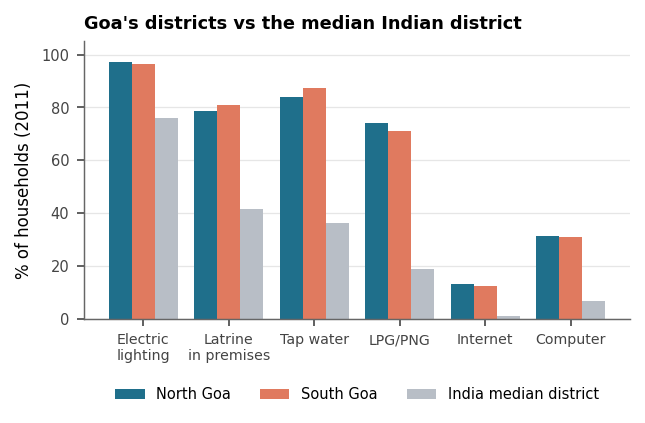

In [19]:
d = pd.read_csv(DIST_CSV)
size_cols = ["Household_size_1_to_2_persons", "Household_size_3_to_5_persons_Households",
             "Household_size_6_8_persons_Households", "Household_size_9_persons_and_above_Households"]
d = d.assign(hh=d[size_cols].sum(axis=1))      # the file's 'Households' column overstates totals; see README
MEAS = {"Electric lighting": "Housholds_with_Electric_Lighting",
        "Latrine in premises": "Having_latrine_facility_within_the_premises_Total_Households",
        "Tap water": "Main_source_of_drinking_water_Tapwater_Households",
        "LPG/PNG": "LPG_or_PNG_Households", "Internet": "Households_with_Internet", "Computer": "Households_with_Computer"}
pct = pd.DataFrame({k: d[c] / d.hh * 100 for k, c in MEAS.items()})
pct["state"], pct["district"] = d["State name"].str.title(), d["District name"]
goa = pct[pct.state == "Goa"].set_index("district")[list(MEAS)]
BENCH = goa.T
BENCH["India median district"] = pct[list(MEAS)].median()
for dist in goa.index:
    BENCH[f"{dist} percentile"] = [(pct[m] < goa.loc[dist, m]).mean() * 100 for m in MEAS]
print(f"India total households (check vs official 24.67 crore): {d.hh.sum() / 1e7:.2f} crore")
display(BENCH.round(1))

fig, ax = plt.subplots(figsize=(COL1 + 1.2, 2.4))
xi = np.arange(len(MEAS))
for k, (col, c) in enumerate(zip(["North Goa", "South Goa", "India median district"], [NORTH, SOUTH, GREY])):
    ax.bar(xi + (k - 1) * 0.27, BENCH[col], 0.27, color=c, label=col)
ax.set_xticks(xi, [m.replace(" in premises", "\nin premises").replace("Electric ", "Electric\n") for m in MEAS], fontsize=6.8)
ax.grid(axis="x", visible=False); ax.set_ylim(0, 105)
ax.set_ylabel("% of households (2011)")
ax.set_title("Goa's districts vs the median Indian district")
ax.legend(loc="upper center", ncol=3, bbox_to_anchor=(0.5, -0.2))
savefig(fig, "fig10_district_benchmark.png")

### 10b. Real-world corroboration after 2011

The model only sees 2011 data. A strong test is whether the towns and facilities it prioritises were later the subject of government action or documented public demand. We searched news and government sources for each town in the greedy K = 10 plan (Section 9), and applied the same search protocol to four **randomly drawn control towns** that are not in the plan. Samples are small, so the comparison is descriptive.

In [20]:
# match = "exact" when the evidence concerns the same facility type the plan assigns,
#         "related" when it concerns a lesser facility of the same kind (e.g. emergency care or a dispensary for a hospital)
EVIDENCE = pd.DataFrame([
    ("Cuncolim", "Fire station", "exact", "MHA fire hazard and risk analysis recommended an urban fire station; DFES later commissioned one",
     "dfes.goa.gov.in/?p=16254"),
    ("Cuncolim", "Hospital", "related", "Local MLA (2021): a 24x7 emergency care centre was a long-pending demand",
     "thegoan.net/goa-news/.../74394.html"),
    ("Quepem", "Hospital", "exact", "Residents demanded a 30-bed hospital; a completed health centre stood unopened for years",
     "heraldgoa.in/goa/when-will-quepem-get-a-full-fledged-health-centre/73538"),
    ("Curchorem-Cacora", "Hospital", "exact", "Community health centre upgraded to 82 beds, announced as Goa's second sub-district hospital",
     "heraldgoa.in/goa/curchorem-to-have-goas-second-sub-district-hospital/272916"),
    ("Usgao", "Fire station", "exact", "DFES 25-year retrospective: a fire station at Usgaon is being proposed",
     "dfes.goa.gov.in (25 years of Goa Fire & Emergency Services, 2025)"),
    ("Sancoale", "Hospital", "related", "Government takeover of the local dispensary was a long-pending demand; sarpanch asked for beds and night doctors",
     "heraldgoa.in/goa/row-over-sancoale-dispensary-takeover/313360"),
    ("Sanquelim", "Hospital", "related", "GSIDC project for reconstruction / upgradation of the Primary Health Centre at Sanquelim",
     "gsidcltd.com/project/page/78"),
], columns=["town", "facility", "match", "evidence (post-2011)", "source"])

plan10 = PLANS[("Greedy optimiser", 10)][["step", "town", "action"]]
CHK = plan10.merge(EVIDENCE[["town", "facility", "match", "evidence (post-2011)"]], left_on=["town", "action"],
                   right_on=["town", "facility"], how="left").drop(columns="facility")
CHK["corroborated"] = CHK["evidence (post-2011)"].notna()
CHK["match"] = CHK["match"].fillna("none")
searched = set(EVIDENCE.town)
CHK.loc[CHK.town.isin(searched) & ~CHK.corroborated, "evidence (post-2011)"] = "none found in our search"
CHK.loc[~CHK.town.isin(searched), "evidence (post-2011)"] = "not searched"
display(CHK)
towns_plan = plan10.town.unique()
exact_towns = set(CHK[CHK.match == "exact"].town)
any_towns = set(CHK[CHK.corroborated].town)
print(f"Plan assignments with exact evidence: {(CHK.match == 'exact').sum()} of {len(CHK)}; "
      f"with exact or related evidence: {CHK.corroborated.sum()} of {len(CHK)}")
print(f"Towns with exact evidence: {len(exact_towns)} of {len(towns_plan)}; with exact or related evidence: "
      f"{len(any_towns)} of {len(towns_plan)} (not searched: {', '.join(sorted(set(towns_plan) - searched)) or 'none'})")
EVIDENCE.to_csv(OUT / "post2011_evidence.csv", index=False)

# ---- control comparison: four towns drawn at random (seed 42) from towns NOT in the plan.
# The same search protocol is applied to the hospital / fire station types each town lacked in 2011.
pool = sorted(set(R.town) - set(towns_plan))
controls = list(np.random.default_rng(SEED).choice(pool, 4, replace=False))
lack = F.set_index("town").loc[controls, ["acc_hospital_km", "acc_fire_km"]] > 0
CONTROL = pd.DataFrame({
    "town": controls,
    "facility types lacking in 2011": [", ".join(n for n, flag in zip(["Hospital", "Fire station"], row) if flag) or "none (ineligible)"
                                        for row in lack.values],
})
CONTROL_FOUND = {"Jua": "none found", "Bandora": "none found", "Onda": "none found", "Ponda": "not applicable"}
CONTROL["post-2011 evidence (same search protocol)"] = CONTROL.town.map(CONTROL_FOUND).fillna("not searched")
display(Markdown("**Randomly drawn control towns (not in the plan)**")); display(CONTROL)
eligible = CONTROL[~CONTROL["facility types lacking in 2011"].str.startswith("none")]
ctrl_hits = (eligible["post-2011 evidence (same search protocol)"] != "none found").sum()
plan_hits = len(exact_towns)
from scipy.stats import fisher_exact
FISHER = fisher_exact([[plan_hits, len(towns_plan) - plan_hits], [ctrl_hits, len(eligible) - ctrl_hits]], alternative="greater")
print(f"Exact evidence: plan towns {plan_hits}/{len(towns_plan)} vs eligible control towns {ctrl_hits}/{len(eligible)} "
      f"(one-sided Fisher exact p = {FISHER.pvalue:.2f}; small samples, descriptive only)")
CONTROL.to_csv(OUT / "post2011_controls.csv", index=False)

,step,town,action,match,evidence (post-2011),corroborated
0,1,Cuncolim,Fire station,exact,MHA fire hazard and risk analysis recommended ...,True
1,2,Sancoale,Fire station,none,none found in our search,False
2,3,Curchorem-Cacora,Hospital,exact,"Community health centre upgraded to 82 beds, a...",True
3,4,Sancoale,Hospital,related,Government takeover of the local dispensary wa...,True
4,5,Usgao,Hospital,none,none found in our search,False
5,6,Quepem,Hospital,exact,Residents demanded a 30-bed hospital; a comple...,True
6,7,Cuncolim,Hospital,related,Local MLA (2021): a 24x7 emergency care centre...,True
7,8,Usgao,Fire station,exact,DFES 25-year retrospective: a fire station at ...,True
8,9,Quepem,Fire station,none,none found in our search,False
9,10,Sanquelim,Hospital,related,GSIDC project for reconstruction / upgradation...,True


Plan assignments with exact evidence: 4 of 10; with exact or related evidence: 7 of 10
Towns with exact evidence: 4 of 6; with exact or related evidence: 6 of 6 (not searched: none)


**Randomly drawn control towns (not in the plan)**

,town,facility types lacking in 2011,post-2011 evidence (same search protocol)
0,Jua,"Hospital, Fire station",none found
1,Bandora,"Hospital, Fire station",none found
2,Onda,"Hospital, Fire station",none found
3,Ponda,none (ineligible),not applicable


Exact evidence: plan towns 4/6 vs eligible control towns 0/3 (one-sided Fisher exact p = 0.12; small samples, descriptive only)


## 11. Export results

In [21]:
R.round(2).to_csv(OUT / "infrascore_rankings.csv", index=False)
GAP.round(2).to_csv(OUT / "gap_analysis.csv", index=False)
GAP_TAB.round(4).to_csv(OUT / "gap_model_comparison.csv", index=False)
ABL_TAB.round(4).to_csv(OUT / "gap_model_ablation.csv", index=False)
COEF.round(4).to_csv(OUT / "gap_model_drivers.csv", index=False)
CL_TAB.round(4).to_csv(OUT / "clustering_comparison.csv", index=False)
CL_PROF.to_csv(OUT / "cluster_profiles.csv")
UA_TAB.round(4).to_csv(OUT / "uncertainty_analysis.csv", index=False)
FAC_TAB.round(4).to_csv(OUT / "facility_model_metrics.csv", index=False)
CAND.round(3).to_csv(OUT / "facility_candidate_sites.csv", index=False)
SIM.round(4).to_csv(OUT / "policy_simulation.csv", index=False)
COST_TAB.round(4).to_csv(OUT / "policy_simulation_costed.csv", index=False)
MC.round(4).to_csv(OUT / "policy_cost_scenarios.csv", index=False)
PLANS[("Greedy optimiser", 10)].round(3).to_csv(OUT / "greedy_plan_K10.csv", index=False)
VAL.round(4).to_csv(OUT / "validation_literacy.csv", index=False)
BENCH.round(2).to_csv(OUT / "district_benchmark.csv")
F.round(4).to_csv(OUT / "features.csv", index=False)
print(f"Saved {len(list(OUT.glob('*.csv')))} tables and {len(list(FIG.glob('*.png')))} figures to {OUT}")
print(f"Total runtime: {time.time() - T0:.0f} s")

Saved 19 tables and 10 figures to /home/claude/final/outputs
Total runtime: 218 s


## 12. Summary of findings

The cell below prints the headline numbers used in the report, so every figure quoted in the paper can be traced to this run.

In [22]:
g10 = PLANS[("Greedy optimiser", 10)]
s10 = SIM[SIM.budget_K == 10].set_index("strategy")
print(f"""
INFRASCORE   mean {R.infrascore.mean():.1f} (SD {R.infrascore.std():.1f}); top: {', '.join(R.town.head(3))}; bottom: {', '.join(R.town.tail(3))}
             statutory {R[R.civic_status != 'Census Town'].infrascore.mean():.1f} vs census towns {R[R.civic_status == 'Census Town'].infrascore.mean():.1f}
ROBUSTNESS   3,600 scenarios, median rho {UA_TAB.median_rho.median():.3f}, worst {UA_TAB.min_rho.min():.3f}; median 90% band {(R.rank_p95 - R.rank_p05).median():.0f} ranks
TYPOLOGIES   {best_method} k=4, silhouette {CL_TAB[(CL_TAB.method == best_method) & (CL_TAB.k == 4)].silhouette.iloc[0]:.2f}, bootstrap ARI {stab[best_method][0]:.2f}
GAP MODEL    {BEST}: MAE {best_mae:.2f} vs baseline {base_mae:.2f}, R2 {GAP_TAB.set_index('model').loc[BEST, 'R2']:.2f}; 90% band +/-{q90:.1f}
             significantly under-served: {', '.join(GAP[GAP.flag == 'Significantly under-served'].town) or 'none'}
             largest negative gaps: {', '.join(GAP.town.head(5))}
FACILITIES   {best_clf}: mean ROC-AUC {FAC_TAB[FAC_TAB.model == best_clf].ROC_AUC.mean():.2f}; {len(CAND)} candidate sites
POLICY K=10  pop-weighted gain: greedy {s10.loc['Greedy optimiser', 'pop_weighted_gain']:.2f} | largest-first {s10.loc['Largest towns first', 'pop_weighted_gain']:.2f} | lowest-first {s10.loc['Lowest score first', 'pop_weighted_gain']:.2f} | random {s10.loc['Random (mean)', 'pop_weighted_gain']:.2f}
COSTED       budget {BUDGET:g} units: cost-aware greedy {COST_TAB.set_index('strategy').loc['Cost-aware greedy', 'pop_weighted_gain']:.2f} | ignores-cost {COST_TAB.set_index('strategy').loc['Greedy (ignores cost)', 'pop_weighted_gain']:.2f} | lowest-first {COST_TAB.set_index('strategy').loc['Lowest score first', 'pop_weighted_gain']:.2f} | random {COST_TAB.set_index('strategy').loc['Random', 'pop_weighted_gain']:.2f}
             wins in 200 cost scenarios vs: {', '.join(f'{k} {v:.0%}' for k, v in win.items())}
EVIDENCE     plan assignments after 2011: exact {(CHK.match == 'exact').sum()} of {len(CHK)}, exact or related {CHK.corroborated.sum()} of {len(CHK)}; towns exact {len(exact_towns)} of {len(towns_plan)}, exact or related {len(any_towns)} of {len(towns_plan)}; random controls {ctrl_hits} of {len(eligible)} (Fisher p = {FISHER.pvalue:.2f})
VALIDATION   literacy rho {VAL.iloc[0].spearman_rho:.2f} (p={VAL.iloc[0].p:.3f}); partial (size-controlled) {VAL.iloc[0].partial_rho_ctrl_size:.2f} (p={VAL.iloc[0].p_partial:.3f})
""")


INFRASCORE   mean 40.4 (SD 10.8); top: Panaji, Margao, Mapusa; bottom: Pale, Candola, Marcaim
             statutory 51.1 vs census towns 37.7
ROBUSTNESS   3,600 scenarios, median rho 0.871, worst 0.587; median 90% band 27 ranks
TYPOLOGIES   K-Means k=4, silhouette 0.19, bootstrap ARI 0.59
GAP MODEL    Lasso: MAE 6.80 vs baseline 8.53, R2 0.24; 90% band +/-13.1
             significantly under-served: Cuncolim, Quepem, Sancoale
             largest negative gaps: Cuncolim, Quepem, Sancoale, Cumbarjua, Arambol
FACILITIES   Logistic (L2): mean ROC-AUC 0.69; 61 candidate sites
POLICY K=10  pop-weighted gain: greedy 0.76 | largest-first 0.05 | lowest-first 0.40 | random 0.18
COSTED       budget 20 units: cost-aware greedy 0.64 | ignores-cost 0.50 | lowest-first 0.21 | random 0.16
             wins in 200 cost scenarios vs: Greedy (ignores cost) 99%, Lowest score first 100%, Random 100%
EVIDENCE     plan assignments after 2011: exact 4 of 10, exact or related 7 of 10; towns exact 4 of 6, e